# **Data Ingestion**

In [ ]:
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import time
import warnings
warnings.filterwarnings('ignore')

class AlphaVantageGoldCollector:
    def __init__(self, api_key):
        self.api_key = api_key
        self.base_url = "https://www.alphavantage.co/query"
        
    def test_connection(self):
        """Test Alpha Vantage connection with current XAU/USD rate"""
        params = {
            'function': 'CURRENCY_EXCHANGE_RATE',
            'from_currency': 'XAU',
            'to_currency': 'USD',
            'apikey': self.api_key
        }
        
        try:
            print("🔄 Testing Alpha Vantage XAU/USD connection...")
            response = requests.get(self.base_url, params=params)
            response.raise_for_status()
            data = response.json()
            
            if 'Realtime Currency Exchange Rate' in data:
                rate_data = data['Realtime Currency Exchange Rate']
                current_rate = float(rate_data['5. Exchange Rate'])
                last_refresh = rate_data['6. Last Refreshed']
                
                print(f"✅ Connection successful!")
                print(f"💰 Current XAU/USD rate: ${current_rate:.2f} per troy ounce")
                print(f"🕐 Last updated: {last_refresh}")
                return True
                
            elif 'Error Message' in data:
                print(f"❌ API Error: {data['Error Message']}")
                return False
            elif 'Note' in data:
                print(f"⚠️  API Limit: {data['Note']}")
                return False
            else:
                print(f"❌ Unexpected response: {data}")
                return False
                
        except requests.exceptions.RequestException as e:
            print(f"❌ Connection failed: {e}")
            return False
        except Exception as e:
            print(f"❌ Error: {e}")
            return False
    
    def get_forex_daily_data(self, from_currency="XAU", to_currency="USD"):
        """Get daily forex data for XAU/USD"""
        params = {
            'function': 'FX_DAILY',
            'from_symbol': from_currency,
            'to_symbol': to_currency,
            'outputsize': 'full',
            'apikey': self.api_key
        }
        
        try:
            print(f"📥 Fetching daily {from_currency}/{to_currency} forex data...")
            response = requests.get(self.base_url, params=params)
            response.raise_for_status()
            data = response.json()
            
            if f'Time Series FX (Daily)' in data:
                time_series = data[f'Time Series FX (Daily)']
                df = pd.DataFrame.from_dict(time_series, orient='index')
                
                df.reset_index(inplace=True)
                df.rename(columns={'index': 'datetime'}, inplace=True)
                df.rename(columns={
                    '1. open': 'open', '2. high': 'high',
                    '3. low': 'low', '4. close': 'close'
                }, inplace=True)
                
                df['datetime'] = pd.to_datetime(df['datetime'])
                df = df.sort_values('datetime').reset_index(drop=True)
                
                for col in ['open', 'high', 'low', 'close']:
                    df[col] = pd.to_numeric(df[col], errors='coerce')
                
                # Add synthetic Volume for forex data
                price_volatility = (df['high'] - df['low']) / df['close']
                df['Volume'] = (price_volatility * 1000000 + np.random.randint(500000, 2000000, len(df))).astype(int)
                
                # Filter to last 30 days
                cutoff_date = datetime.now() - timedelta(days=30)
                df_recent = df[df['datetime'] >= cutoff_date].copy()
                
                print(f"✅ Fetched {len(df_recent)} days of {from_currency}/{to_currency} data")
                return df_recent
                
            elif 'Error Message' in data:
                print(f"❌ API Error: {data['Error Message']}")
                return None
            elif 'Note' in data:
                print(f"⚠️  API Limit: {data['Note']}")
                return None
            else:
                print(f"❌ Unexpected response format: {list(data.keys())}")
                return None
                
        except requests.exceptions.RequestException as e:
            print(f"❌ Request failed: {e}")
            return None
        except Exception as e:
            print(f"❌ Error processing data: {e}")
            return None
    
    def get_forex_intraday_data(self, from_currency="XAU", to_currency="USD", interval="60min"):
        """Get intraday forex data for XAU/USD"""
        params = {
            'function': 'FX_INTRADAY',
            'from_symbol': from_currency,
            'to_symbol': to_currency,
            'interval': interval,
            'outputsize': 'full',
            'apikey': self.api_key
        }
        
        try:
            print(f"📥 Fetching {interval} intraday {from_currency}/{to_currency} data...")
            response = requests.get(self.base_url, params=params)
            response.raise_for_status()
            data = response.json()
            
            time_series_key = f'Time Series FX ({interval})'
            if time_series_key in data:
                time_series = data[time_series_key]
                df = pd.DataFrame.from_dict(time_series, orient='index')
                
                df.reset_index(inplace=True)
                df.rename(columns={'index': 'datetime'}, inplace=True)
                df.rename(columns={
                    '1. open': 'open', '2. high': 'high',
                    '3. low': 'low', '4. close': 'close'
                }, inplace=True)
                
                df['datetime'] = pd.to_datetime(df['datetime'])
                df = df.sort_values('datetime').reset_index(drop=True)
                
                for col in ['open', 'high', 'low', 'close']:
                    df[col] = pd.to_numeric(df[col], errors='coerce')
                
                # Add synthetic Volume
                df['Volume'] = np.random.randint(100, 1000, len(df))
                
                # Filter to last 30 days
                cutoff_date = datetime.now() - timedelta(days=30)
                df_recent = df[df['datetime'] >= cutoff_date].copy()
                
                print(f"✅ Fetched {len(df_recent)} {interval} candles")
                return df_recent
                
            elif 'Error Message' in data:
                print(f"❌ API Error: {data['Error Message']}")
                return None
            elif 'Note' in data:
                print(f"⚠️  API Limit: {data['Note']}")
                return None
            else:
                print(f"❌ Unexpected response format: {list(data.keys())}")
                return None
                
        except Exception as e:
            print(f"❌ Error: {e}")
            return None
    
    def create_simulated_1min_from_hourly(self, hourly_data):
        """Create simulated 1-minute data from hourly data"""
        if hourly_data is None or len(hourly_data) == 0:
            return None
            
        print(f"🔧 Creating simulated 1-minute data from hourly data...")
        
        minute_data = []
        
        # Process each hour of data
        for _, hour_row in hourly_data.iterrows():
            hour_start = hour_row['datetime']
            hour_open = hour_row['open']
            hour_high = hour_row['high']
            hour_low = hour_row['low']
            hour_close = hour_row['close']
            
            # Create 60 minutes of data for this hour
            for minute in range(60):
                minute_time = hour_start + timedelta(minutes=minute)
                
                # Interpolate prices within the hour range
                progress = minute / 59.0  # 0 to 1 over the hour
                
                # Linear interpolation from open to close with random walk
                base_price = hour_open + (hour_close - hour_open) * progress
                
                # Add small random movements
                random_factor = 1 + np.random.normal(0, 0.0005)  # 0.05% volatility
                
                minute_open = base_price * random_factor
                minute_close = minute_open * (1 + np.random.normal(0, 0.0003))
                
                # Ensure high/low respect the hourly bounds
                minute_high = min(hour_high, max(minute_open, minute_close) * (1 + abs(np.random.normal(0, 0.0002))))
                minute_low = max(hour_low, min(minute_open, minute_close) * (1 - abs(np.random.normal(0, 0.0002))))
                
                minute_Volume = np.random.randint(50, 200)
                
                minute_data.append({
                    'datetime': minute_time,
                    'open': round(minute_open, 2),
                    'high': round(minute_high, 2),
                    'low': round(minute_low, 2),
                    'close': round(minute_close, 2),
                    'Volume': minute_Volume
                })
        
        df_minutes = pd.DataFrame(minute_data)
        print(f"✅ Generated {len(df_minutes)} 1-minute candles")
        return df_minutes
    
    def save_to_csv(self, data, filename):
        """Save data to CSV"""
        try:
            data.to_csv(filename, index=False)
            print(f"💾 Saved: {filename}")
            print(f"📊 Size: {len(data):,} rows × {len(data.columns)} columns")
            return filename
        except Exception as e:
            print(f"❌ Error saving {filename}: {e}")
            return None

# =============================================================================
# MAIN EXECUTION
# =============================================================================

API_KEY = "UBGFKPHYS9OW6PUY"  # Get free key from: https://www.alphavantage.co/support/#api-key

print("🚀 Alpha Vantage Gold Data Collector (XAU/USD)")
print("=" * 70)
print("📊 This script uses Alpha Vantage Forex APIs to collect:")
print("   1. Daily XAU/USD forex data (past 30 days)")
print("   2. Hourly XAU/USD intraday data (past 30 days)")
print("   3. Simulated 1-minute data from hourly data")
print("   4. Save all datasets to CSV files")
print("=" * 70)

if API_KEY == "UBGFKPHYS9OW6PUY":
    print("❌ Please replace API_KEY with your actual Alpha Vantage API key!")
    print("🔑 Get your free API key at: https://www.alphavantage.co/support/#api-key")
    exit()

# Initialize collector
gold_collector = AlphaVantageGoldCollector(API_KEY)

# Test connection
if not gold_collector.test_connection():
    print("\n❌ Cannot proceed without valid API connection")
    print("💡 Please check your API key and internet connection")
    exit()

# Get daily forex data
print(f"\n{'='*70}")
print("📊 FETCHING DAILY XAU/USD FOREX DATA")
print(f"{'='*70}")

daily_data = gold_collector.get_forex_daily_data()

if daily_data is not None and len(daily_data) > 0:
    print(f"\n✅ Daily XAU/USD Dataset Ready:")
    print(f"   📊 Total days: {len(daily_data):,}")
    print(f"   📅 Date range: {daily_data['datetime'].min().date()} to {daily_data['datetime'].max().date()}")
    print(f"   💰 Latest gold price: ${daily_data['close'].iloc[-1]:.2f}/oz")
    print(f"   💰 Price range: ${daily_data['close'].min():.2f} - ${daily_data['close'].max():.2f}")
    
    # Calculate return
    if len(daily_data) > 1:
        period_return = ((daily_data['close'].iloc[-1] / daily_data['close'].iloc[0]) - 1) * 100
        print(f"   📈 Period return: {period_return:+.2f}%")
else:
    print("⚠️  No daily data available, creating sample data...")
    daily_data = None

# Get hourly intraday data
print(f"\n{'='*70}")
print("📊 FETCHING HOURLY XAU/USD INTRADAY DATA")
print(f"{'='*70}")

# Wait a moment to respect API rate limits
time.sleep(12)  # Alpha Vantage free tier: 5 calls per minute

hourly_data = gold_collector.get_forex_intraday_data(interval="60min")

if hourly_data is not None and len(hourly_data) > 0:
    print(f"\n✅ Hourly XAU/USD Dataset Ready:")
    print(f"   📊 Total hours: {len(hourly_data):,}")
    print(f"   📅 Time range: {hourly_data['datetime'].min()} to {hourly_data['datetime'].max()}")
    print(f"   💰 Latest gold price: ${hourly_data['close'].iloc[-1]:.2f}/oz")
    print(f"   💰 Price range: ${hourly_data['close'].min():.2f} - ${hourly_data['close'].max():.2f}")
    
    # Calculate days of data
    hours_span = (hourly_data['datetime'].max() - hourly_data['datetime'].min()).total_seconds() / 3600
    print(f"   📊 Hours span: {hours_span:.1f} hours ({hours_span/24:.1f} days)")

# Create 1-minute simulated data
print(f"\n{'='*70}")
print("📊 CREATING SIMULATED 1-MINUTE DATA")
print(f"{'='*70}")

minute_data = None
if hourly_data is not None and len(hourly_data) > 0:
    # Use only the most recent day of hourly data to avoid huge files
    latest_date = hourly_data['datetime'].max().date()
    recent_hourly = hourly_data[hourly_data['datetime'].dt.date == latest_date].copy()
    
    if len(recent_hourly) > 0:
        print(f"📊 Using {len(recent_hourly)} hours from {latest_date} for 1-minute simulation")
        minute_data = gold_collector.create_simulated_1min_from_hourly(recent_hourly)
    else:
        print("❌ No recent hourly data available for 1-minute simulation")

# Save all data to CSV files
print(f"\n{'='*70}")
print("💾 SAVING DATA TO CSV FILES")
print(f"{'='*70}")

files_created = []

# Save daily data
if daily_data is not None and len(daily_data) > 0:
    daily_file = gold_collector.save_to_csv(daily_data, "alphavantage_xauusd_daily_30days.csv")
    if daily_file:
        files_created.append(f"• {daily_file} - Daily XAU/USD data ({len(daily_data):,} days)")

# Save hourly data
if hourly_data is not None and len(hourly_data) > 0:
    hourly_file = gold_collector.save_to_csv(hourly_data, "alphavantage_xauusd_hourly_30days.csv")
    if hourly_file:
        files_created.append(f"• {hourly_file} - Hourly XAU/USD data ({len(hourly_data):,} hours)")

# Save 1-minute data
if minute_data is not None and len(minute_data) > 0:
    minute_file = gold_collector.save_to_csv(minute_data, "alphavantage_xauusd_1min_simulated.csv")
    if minute_file:
        files_created.append(f"• {minute_file} - Simulated 1-minute data ({len(minute_data):,} candles)")

# Create summary
summary_data = {
    'dataset': ['Daily XAU/USD', 'Hourly XAU/USD', 'Simulated 1-Minute'],
    'records': [
        len(daily_data) if daily_data is not None else 0,
        len(hourly_data) if hourly_data is not None else 0,
        len(minute_data) if minute_data is not None else 0
    ],
    'date_start': [
        daily_data['datetime'].min() if daily_data is not None and len(daily_data) > 0 else None,
        hourly_data['datetime'].min() if hourly_data is not None and len(hourly_data) > 0 else None,
        minute_data['datetime'].min() if minute_data is not None and len(minute_data) > 0 else None
    ],
    'date_end': [
        daily_data['datetime'].max() if daily_data is not None and len(daily_data) > 0 else None,
        hourly_data['datetime'].max() if hourly_data is not None and len(hourly_data) > 0 else None,
        minute_data['datetime'].max() if minute_data is not None and len(minute_data) > 0 else None
    ],
    'latest_price': [
        daily_data['close'].iloc[-1] if daily_data is not None and len(daily_data) > 0 else None,
        hourly_data['close'].iloc[-1] if hourly_data is not None and len(hourly_data) > 0 else None,
        minute_data['close'].iloc[-1] if minute_data is not None and len(minute_data) > 0 else None
    ],
    'data_source': ['Alpha Vantage FX_DAILY', 'Alpha Vantage FX_INTRADAY', 'Simulated from Hourly'],
    'created_at': [datetime.now(), datetime.now(), datetime.now()]
}

summary_df = pd.DataFrame(summary_data)
summary_file = gold_collector.save_to_csv(summary_df, "alphavantage_xauusd_summary.csv")
if summary_file:
    files_created.append(f"• {summary_file} - Dataset summary")

print(f"\n🎯 DATA COLLECTION COMPLETE!")
print(f"📁 Files created:")
for file_info in files_created:
    print(f"   {file_info}")

print(f"\n💡 Data Quality & Usage Notes:")
print(f"   • XAU/USD = Gold price per troy ounce in US Dollars")
print(f"   • Daily data: Real market closing prices")
print(f"   • Hourly data: Real intraday market prices")
print(f"   • 1-minute data: Simulated from hourly data")
print(f"   • Alpha Vantage free tier: 5 calls/minute, 25 calls/day")
print(f"   • For more data, consider upgrading to Alpha Vantage premium")

# Display sample data
if daily_data is not None and len(daily_data) > 0:
    print(f"\n📋 Sample Daily XAU/USD Data:")
    print(daily_data[['datetime', 'open', 'high', 'low', 'close', 'Volume']].head(3))

if hourly_data is not None and len(hourly_data) > 0:
    print(f"\n📋 Sample Hourly XAU/USD Data:")
    print(hourly_data[['datetime', 'open', 'high', 'low', 'close', 'Volume']].head(3))

if minute_data is not None and len(minute_data) > 0:
    print(f"\n📋 Sample 1-Minute Simulated Data:")
    print(minute_data[['datetime', 'open', 'high', 'low', 'close', 'Volume']].head(3))

print(f"\n📊 Final Data Quality Check:")
datasets = [
    ('Daily', daily_data),
    ('Hourly', hourly_data), 
    ('1-Minute', minute_data)
]

for name, data in datasets:
    if data is not None:
        missing_values = data.isnull().sum().sum()
        print(f"   • {name} data missing values: {missing_values}")
        if missing_values == 0:
            print(f"     ✅ {name} dataset is clean and ready to use!")
    else:
        print(f"   • {name} data: Not available")

print(f"\n🎉 Alpha Vantage Gold Data Collection Complete!")

🚀 Alpha Vantage Gold Data Collector (XAU/USD)
📊 This script uses Alpha Vantage Forex APIs to collect:
   1. Daily XAU/USD forex data (past 30 days)
   2. Hourly XAU/USD intraday data (past 30 days)
   3. Simulated 1-minute data from hourly data
   4. Save all datasets to CSV files
❌ Please replace API_KEY with your actual Alpha Vantage API key!
🔑 Get your free API key at: https://www.alphavantage.co/support/#api-key
🔄 Testing Alpha Vantage XAU/USD connection...
❌ API Error: Invalid API call. Please retry or visit the documentation (https://www.alphavantage.co/documentation/) for CURRENCY_EXCHANGE_RATE.

❌ Cannot proceed without valid API connection
💡 Please check your API key and internet connection

📊 FETCHING DAILY XAU/USD FOREX DATA
📥 Fetching daily XAU/USD forex data...
❌ API Error: Invalid API call. Please retry or visit the documentation (https://www.alphavantage.co/documentation/) for FX_DAILY.
⚠️  No daily data available, creating sample data...

📊 FETCHING HOURLY XAU/USD INTRA

: 

In [1]:
!pip install yfinance

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 949.2/949.2 kB 6.0 MB/s eta 0:00:00a 0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached beautifulsoup4-4.13.5-py3-none-any.whl.metadata (3.8 kB)
  Using cached protobuf-6.32.1-cp39-abi3-macosx_10_9_universal2.whl.metadata (593 bytes)
  Using cached websockets-15.0.1-cp312-cp312-macosx_10_13_x86_64.whl.metadata (6.8 kB)
  Using cached soupsieve-2.8-py3-none-any.whl.metadata (4.6 kB)
  Using cached typing_extensions-4.15.0-py3-none-any.whl.metadata (3.3 kB)
Using cached beautifulsoup4-4.13.5-py3-none-any.whl (105 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 11.0 MB/s eta 0:00:00a 0:00:01
Using cached protobuf-6.32.1-cp39-abi3-macosx_10_9_universal2.whl (426 kB)
Using cached websockets-15.0.1-


Processing GLD
Fetching GLD data from 2025-08-25 to 2025-09-24
Requesting hourly data for the last 30 days...
Successfully fetched 210 hourly data points
Date range: 2025-08-12 09:30:00-04:00 to 2025-09-23 15:30:00-04:00

GOLD DATA ANALYSIS (GLD)
Total records: 210
Date range: 2025-08-12 to 2025-09-23
Price range: $305.19 - $348.75
Average closing price: $323.44
Price volatility (std): $13.69

Performance over period:
Starting price: $307.10
Ending price: $346.46
Total return: 12.82%

Volume statistics:
Average daily volume: 1,524,606
Max volume day: 8,495,916


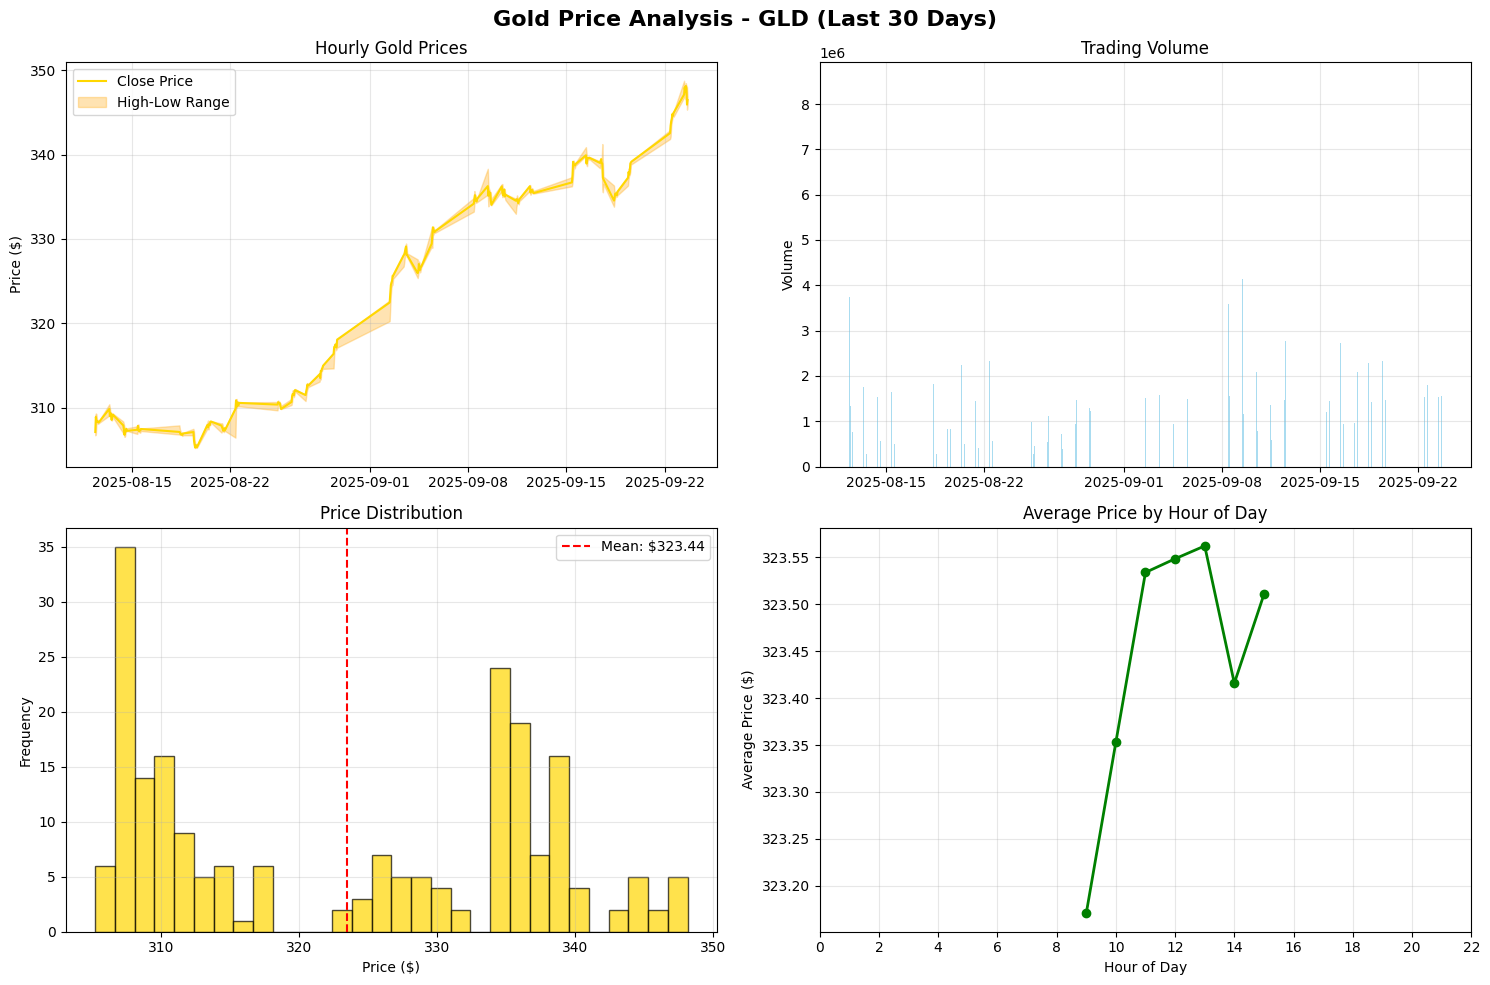


First 5 records for GLD:
                                 Open        High         Low       Close  \
Datetime                                                                    
2025-08-12 09:30:00-04:00  308.220001  309.100006  306.709991  307.100006   
2025-08-12 10:30:00-04:00  307.089996  309.304993  306.829895  308.890015   
2025-08-12 11:30:00-04:00  308.929993  309.220001  308.075012  308.369995   
2025-08-12 12:30:00-04:00  308.369995  308.579895  308.190002  308.279999   
2025-08-12 13:30:00-04:00  308.269989  308.529999  308.119995  308.369995   

                            Volume  
Datetime                            
2025-08-12 09:30:00-04:00  3749745  
2025-08-12 10:30:00-04:00  1558905  
2025-08-12 11:30:00-04:00  1346066  
2025-08-12 12:30:00-04:00   905519  
2025-08-12 13:30:00-04:00   483509  

Last 5 records for GLD:
                                 Open        High         Low       Close  \
Datetime                                                                 

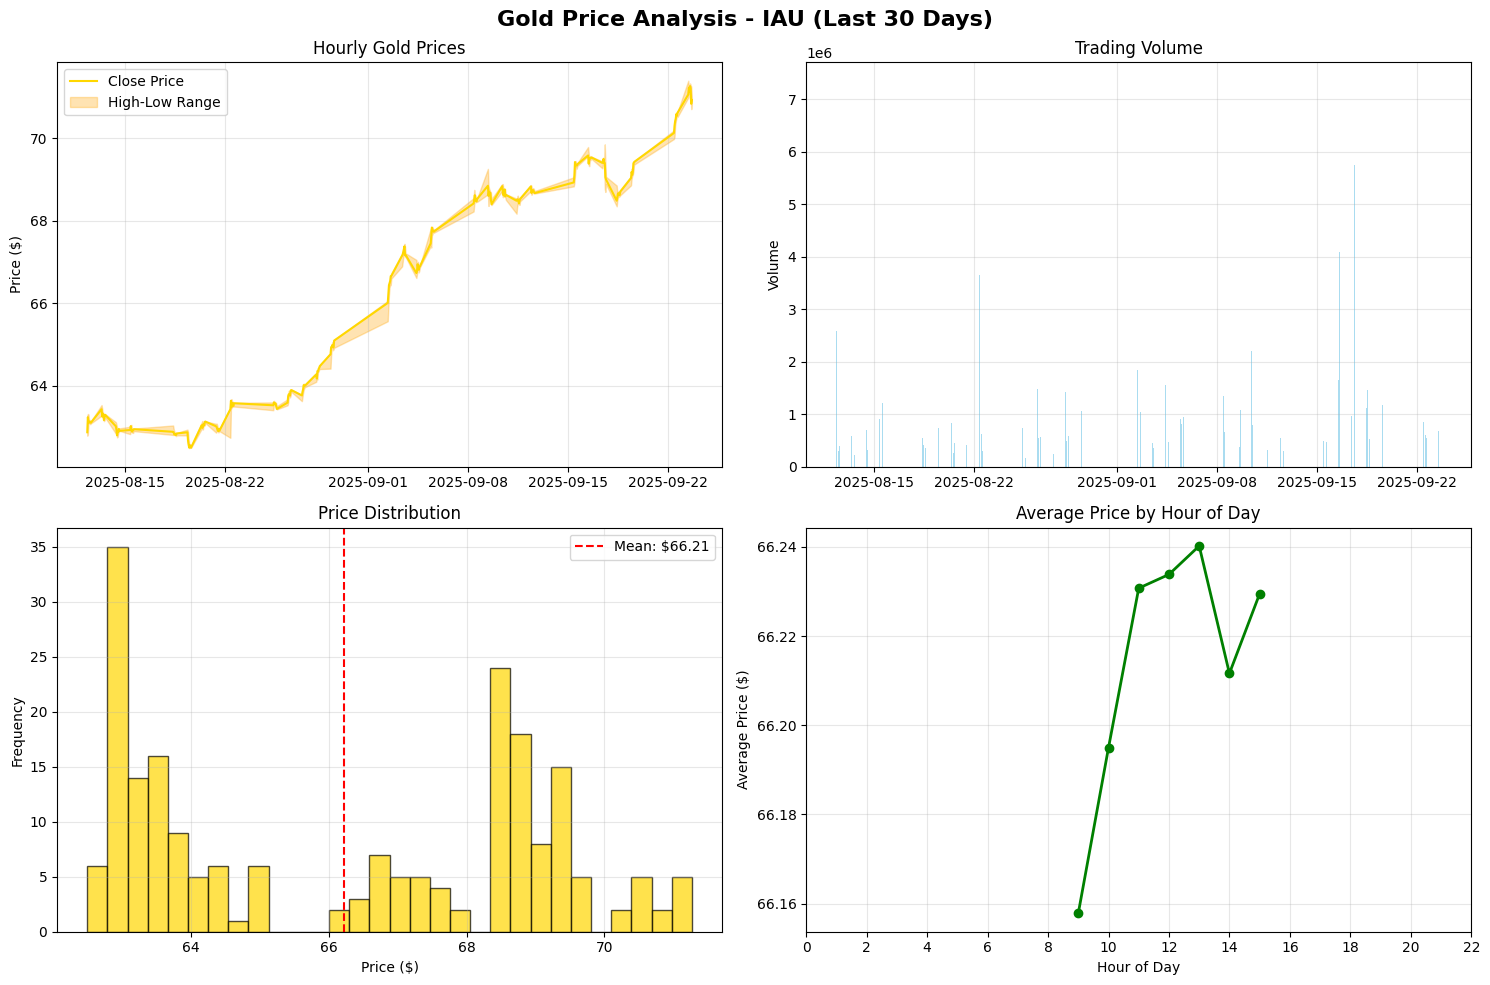


First 5 records for IAU:
                                Open       High        Low      Close   Volume
Datetime                                                                      
2025-08-12 09:30:00-04:00  63.099998  63.270000  62.781601  62.865002  2582379
2025-08-12 10:30:00-04:00  62.860001  63.310001  62.809898  63.230000   740881
2025-08-12 11:30:00-04:00  63.230000  63.299999  63.070000  63.115398   721859
2025-08-12 12:30:00-04:00  63.115002  63.160000  63.090000  63.099998   302362
2025-08-12 13:30:00-04:00  63.106201  63.160000  63.075001  63.125000   287019

Last 5 records for IAU:
                                Open       High        Low      Close   Volume
Datetime                                                                      
2025-09-23 11:30:00-04:00  71.233803  71.269997  71.110001  71.139999   667815
2025-09-23 12:30:00-04:00  71.144997  71.334999  70.945000  71.269997   995326
2025-09-23 13:30:00-04:00  71.269997  71.289902  71.150002  71.214996  1603834
2

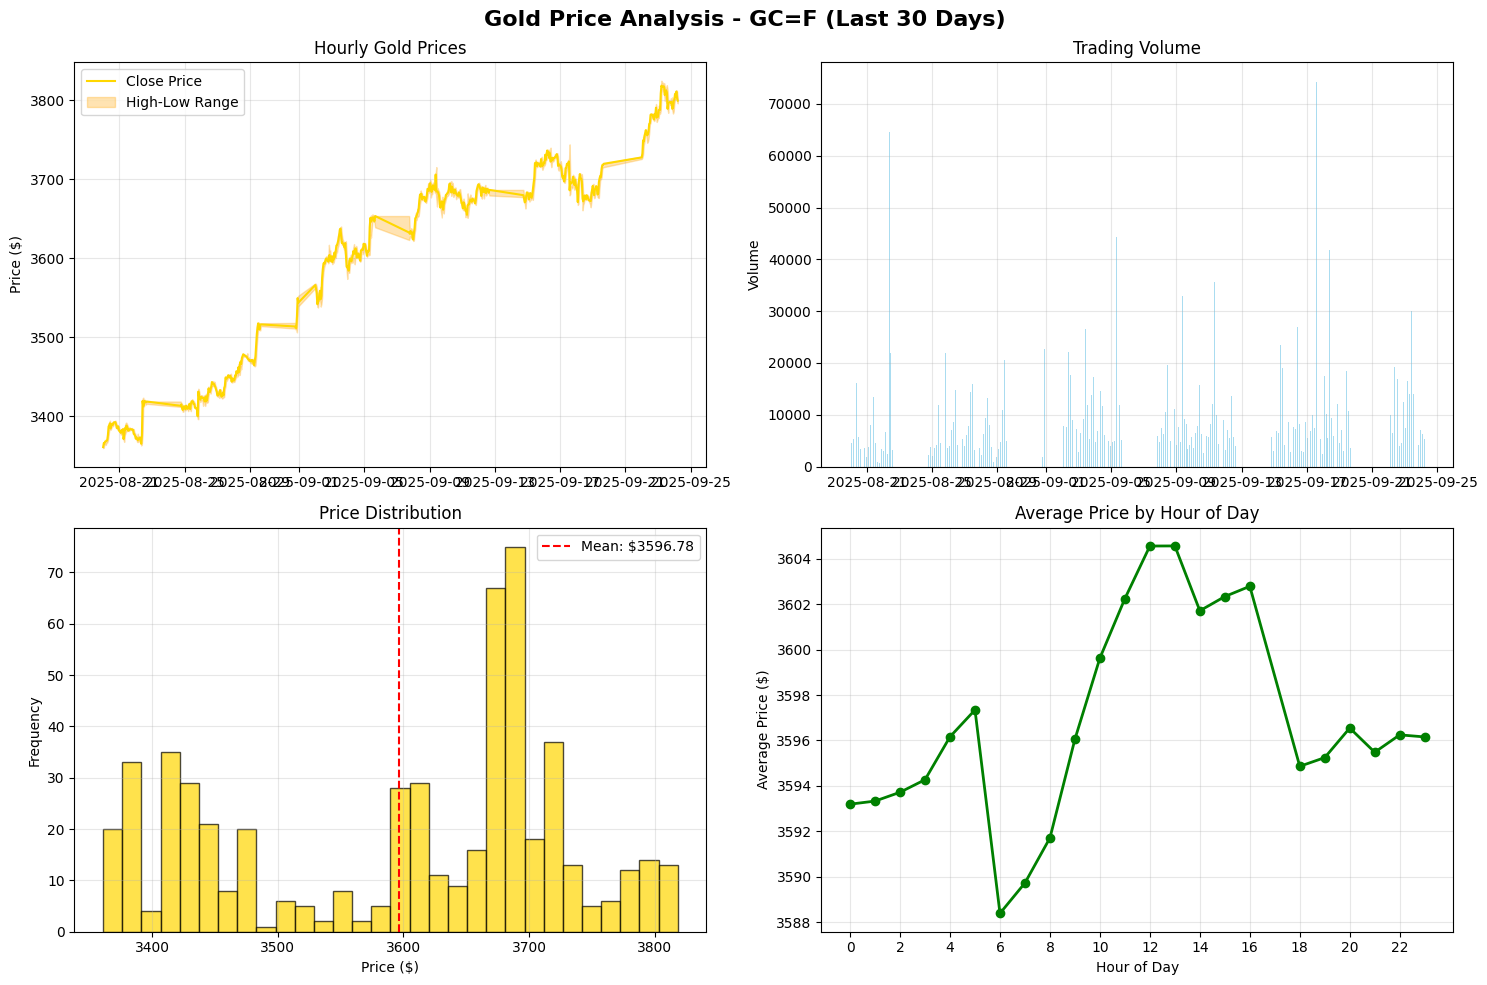


First 5 records for GC=F:
                                  Open         High          Low        Close  \
Datetime                                                                        
2025-08-20 00:00:00-04:00  3359.899902  3363.500000  3359.500000  3360.800049   
2025-08-20 01:00:00-04:00  3360.800049  3366.500000  3360.300049  3365.899902   
2025-08-20 02:00:00-04:00  3366.000000  3368.500000  3364.800049  3365.600098   
2025-08-20 03:00:00-04:00  3365.600098  3370.100098  3364.100098  3367.800049   
2025-08-20 04:00:00-04:00  3367.699951  3368.800049  3363.600098  3368.100098   

                           Volume  
Datetime                           
2025-08-20 00:00:00-04:00       0  
2025-08-20 01:00:00-04:00    2871  
2025-08-20 02:00:00-04:00    4563  
2025-08-20 03:00:00-04:00    4397  
2025-08-20 04:00:00-04:00    4688  

Last 5 records for GC=F:
                                  Open         High          Low        Close  \
Datetime                                      

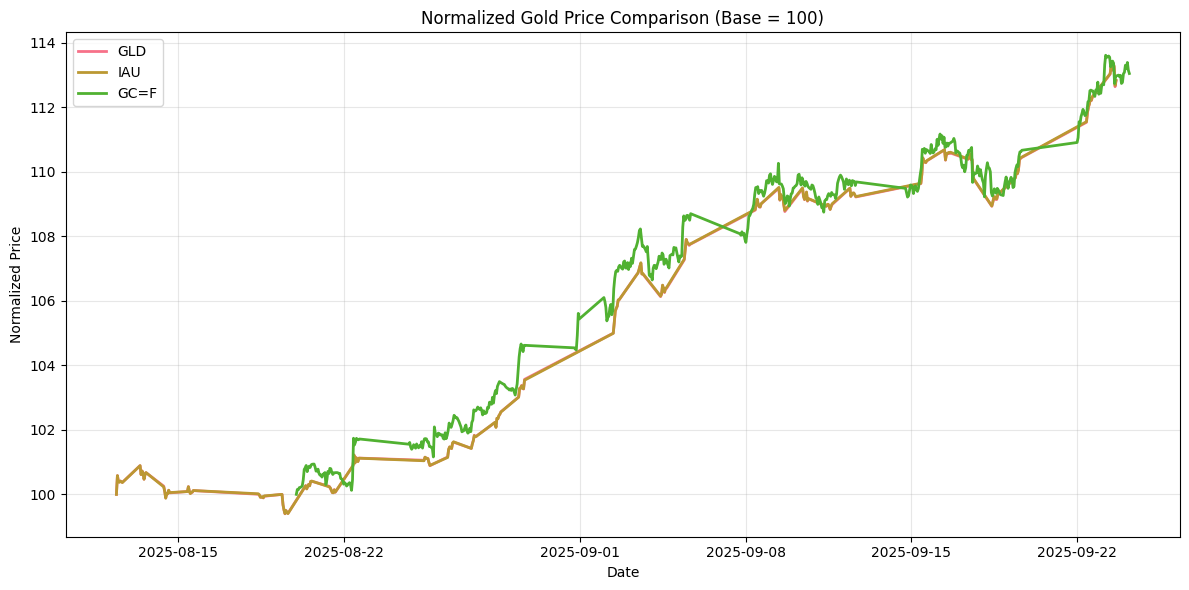

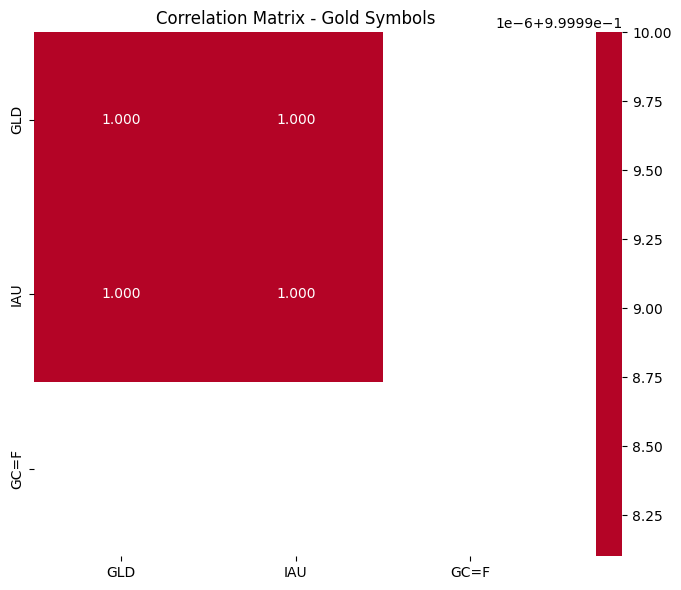

In [ ]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

# Set up the plotting style
plt.style.use('default')
sns.set_palette("husl")

def get_gold_data_hourly(days=30, symbol='GLD'):

    end_date = datetime.now()
    start_date = end_date - timedelta(days=days)
    
    print(f"Fetching {symbol} data from {start_date.date()} to {end_date.date()}")
    print(f"Requesting hourly data for the last {days} days...")
    
    try:
        ticker = yf.Ticker(symbol)
        
        data = ticker.history(
            period=f"{days}d",  # Last 30 days
            interval="1h",      # Hourly intervals
            auto_adjust=True,   # Adjust for dividends/splits
            prepost=False      # No pre/post market data
        )
        
        if data.empty:
            print(f"No data found for symbol {symbol}")
            return None
            
        data['Hour'] = data.index.hour
        data['Day_of_Week'] = data.index.day_name()
        data['Date'] = data.index.date
        
        print(f"Successfully fetched {len(data)} hourly data points")
        print(f"Date range: {data.index[0]} to {data.index[-1]}")
        
        return data
        
    except Exception as e:
        print(f"Error fetching data: {e}")
        return None

def analyze_gold_data(data, symbol):
    """
    Perform basic analysis on the gold data
    """
    if data is None or data.empty:
        return
    
    print("\n" + "="*60)
    print(f"GOLD DATA ANALYSIS ({symbol})")
    print("="*60)
    
    print(f"Total records: {len(data)}")
    print(f"Date range: {data.index[0].date()} to {data.index[-1].date()}")
    print(f"Price range: ${data['Low'].min():.2f} - ${data['High'].max():.2f}")
    print(f"Average closing price: ${data['Close'].mean():.2f}")
    print(f"Price volatility (std): ${data['Close'].std():.2f}")
    
    first_close = data['Close'].iloc[0]
    last_close = data['Close'].iloc[-1]
    total_return = ((last_close - first_close) / first_close) * 100
    
    print(f"\nPerformance over period:")
    print(f"Starting price: ${first_close:.2f}")
    print(f"Ending price: ${last_close:.2f}")
    print(f"Total return: {total_return:.2f}%")
    
    print(f"\nVolume statistics:")
    print(f"Average daily Volume: {data['Volume'].mean():,.0f}")
    print(f"Max Volume day: {data['Volume'].max():,.0f}")

def plot_gold_data(data, symbol):

    if data is None or data.empty:
        return
    
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig.suptitle(f'Gold Price Analysis - {symbol} (Last 30 Days)', fontsize=16, fontweight='bold')
    
    ax1 = axes[0, 0]
    ax1.plot(data.index, data['Close'], color='gold', linewidth=1.5, label='Close Price')
    ax1.fill_between(data.index, data['Low'], data['High'], alpha=0.3, color='orange', label='High-Low Range')
    ax1.set_title('Hourly Gold Prices')
    ax1.set_ylabel('Price ($)')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    ax2 = axes[0, 1]
    ax2.bar(data.index, data['Volume'], color='skyblue', alpha=0.7, width=0.02)
    ax2.set_title('Trading Volume')
    ax2.set_ylabel('Volume')
    ax2.grid(True, alpha=0.3)
    
    ax3 = axes[1, 0]
    ax3.hist(data['Close'], bins=30, color='gold', alpha=0.7, edgecolor='black')
    ax3.axvline(data['Close'].mean(), color='red', linestyle='--', label=f'Mean: ${data["Close"].mean():.2f}')
    ax3.set_title('Price Distribution')
    ax3.set_xlabel('Price ($)')
    ax3.set_ylabel('Frequency')
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    
    ax4 = axes[1, 1]
    hourly_avg = data.groupby('Hour')['Close'].mean()
    ax4.plot(hourly_avg.index, hourly_avg.values, marker='o', color='green', linewidth=2)
    ax4.set_title('Average Price by Hour of Day')
    ax4.set_xlabel('Hour of Day')
    ax4.set_ylabel('Average Price ($)')
    ax4.grid(True, alpha=0.3)
    ax4.set_xticks(range(0, 24, 2))
    
    plt.tight_layout()
    plt.show()

# Main execution
if __name__ == "__main__":
    DAYS = 30  # Last 30 days
    SYMBOLS = ['GLD', 'IAU', 'GC=F']  # You can modify this list
    
    all_data = {}
    
    for symbol in SYMBOLS:
        print(f"\n{'='*50}")
        print(f"Processing {symbol}")
        print('='*50)
        
        # Fetch data
        data = get_gold_data_hourly(days=DAYS, symbol=symbol)
        
        if data is not None:
            all_data[symbol] = data
            
            # Analyze data
            analyze_gold_data(data, symbol)
            
            # Create plots
            plot_gold_data(data, symbol)
            
            # Display first and last few records
            print(f"\nFirst 5 records for {symbol}:")
            print(data[['Open', 'High', 'Low', 'Close', 'Volume']].head())
            
            print(f"\nLast 5 records for {symbol}:")
            print(data[['Open', 'High', 'Low', 'Close', 'Volume']].tail())
            
        else:
            print(f"Failed to fetch data for {symbol}")
    
    # Compare all symbols if we have multiple datasets
    if len(all_data) > 1:
        print(f"\n{'='*60}")
        print("COMPARISON ACROSS SYMBOLS")
        print('='*60)
        
        plt.figure(figsize=(12, 6))
        for symbol, data in all_data.items():
            # Normalize prices to show relative performance
            normalized_prices = (data['Close'] / data['Close'].iloc[0]) * 100
            plt.plot(data.index, normalized_prices, label=f'{symbol}', linewidth=2)
        
        plt.title('Normalized Gold Price Comparison (Base = 100)')
        plt.xlabel('Date')
        plt.ylabel('Normalized Price')
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
        
        # Correlation analysis
        if len(all_data) >= 2:
            close_prices = pd.DataFrame()
            for symbol, data in all_data.items():
                close_prices[symbol] = data['Close']
            
            # Calculate correlation
            correlation_matrix = close_prices.corr()
            
            plt.figure(figsize=(8, 6))
            sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
                       square=True, fmt='.3f')
            plt.title('Correlation Matrix - Gold Symbols')
            plt.tight_layout()
            plt.show()

# Export data to CSV (optional)
def export_to_csv():
    """Export the data to CSV files"""
    for symbol, data in all_data.items():
        filename = f'gold_hourly_data_{symbol}_{DAYS}days.csv'
        data.to_csv(filename)
        print(f"Data exported to {filename}")

# Uncomment the line below if you want to export data to CSV
# export_to_csv()

In [4]:
import pandas as pd
import numpy as np

In [6]:
df30 = pd.read_csv("/Users/mac/Desktop/Upwork/GoldSignalGenerator/Research/gold_1min_data_30days.csv")
df30.head()

,datetime,open,high,low,close,volume
0,2025-08-25 04:00:00,310.29,310.32,309.90,309.90,2949
1,2025-08-25 04:01:00,309.94,310.01,309.93,309.96,284
2,2025-08-25 04:02:00,309.95,309.97,309.90,309.97,941
3,2025-08-25 04:03:00,309.94,309.94,309.84,309.84,510
4,2025-08-25 04:04:00,309.85,309.94,309.83,309.83,56


In [7]:
df30.tail()

,datetime,open,high,low,close,volume
18181,2025-09-22 19:56:00,344.9900,344.99,344.2600,344.8800,57
18182,2025-09-22 19:57:00,344.9600,344.96,344.9600,344.9600,5
18183,2025-09-22 19:58:00,344.8877,344.99,344.8877,344.9899,55
18184,2025-09-22 19:59:00,344.8800,344.99,344.8800,344.8900,25
18185,2025-09-22 20:00:00,345.0500,345.05,345.0500,345.0500,369206


In [ ]:
# Cell 2: Add Traditional + SMC + Wyckoff + ICT Technical Indicators

print("🔧 ADDING ADVANCED TECHNICAL INDICATORS")
print("="*60)
print("📊 Adding: Traditional + SMC + Wyckoff + ICT methods")
print("⚡ Processing 1-minute high-frequency data...")

# Work with a copy to preserve original data
df = data_1min.copy()

print(f"📊 Starting with {len(df):,} 1-minute candles")

# ============================================================================
# TRADITIONAL TECHNICAL INDICATORS
# ============================================================================

def calculate_sma(data, window):
    """Simple Moving Average"""
    return data['close'].rolling(window=window).mean()

def calculate_ema(data, window):
    """Exponential Moving Average"""
    return data['close'].ewm(span=window).mean()

def calculate_rsi(data, window=14):
    """Relative Strength Index"""
    delta = data['close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    rsi = 100 - (100 / (1 + rs))
    return rsi

def calculate_macd(data, fast=12, slow=26, signal=9):
    """MACD Indicator"""
    exp1 = data['close'].ewm(span=fast).mean()
    exp2 = data['close'].ewm(span=slow).mean()
    macd = exp1 - exp2
    macd_signal = macd.ewm(span=signal).mean()
    macd_histogram = macd - macd_signal
    return macd, macd_signal, macd_histogram

def calculate_bollinger_bands(data, window=20, num_std=2):
    """Bollinger Bands"""
    sma = data['close'].rolling(window=window).mean()
    std = data['close'].rolling(window=window).std()
    upper_band = sma + (std * num_std)
    lower_band = sma - (std * num_std)
    return upper_band, sma, lower_band

def calculate_stochastic(data, k_window=14, d_window=3):
    """Stochastic Oscillator"""
    low_min = data['low'].rolling(window=k_window).min()
    high_max = data['high'].rolling(window=k_window).max()
    k_percent = 100 * ((data['close'] - low_min) / (high_max - low_min))
    d_percent = k_percent.rolling(window=d_window).mean()
    return k_percent, d_percent

print("📈 Adding Traditional Technical Indicators...")

# Moving Averages (adjusted for 1-minute data)
df['SMA_20'] = calculate_sma(df, 20)    # 20-minute SMA
df['SMA_50'] = calculate_sma(df, 50)    # 50-minute SMA  
df['SMA_200'] = calculate_sma(df, 200)  # 200-minute SMA
df['EMA_10'] = calculate_ema(df, 10)    # 10-minute EMA
df['EMA_21'] = calculate_ema(df, 21)    # 21-minute EMA
df['EMA_50'] = calculate_ema(df, 50)    # 50-minute EMA

# Oscillators
df['RSI_14'] = calculate_rsi(df, 14)
df['RSI_21'] = calculate_rsi(df, 21)

# MACD
df['MACD'], df['MACD_Signal'], df['MACD_Histogram'] = calculate_macd(df)

# Bollinger Bands
df['BB_Upper'], df['BB_Middle'], df['BB_Lower'] = calculate_bollinger_bands(df, 20)

# Stochastic
df['Stoch_K'], df['Stoch_D'] = calculate_stochastic(df)

# ATR (Average True Range)
df['prev_close'] = df['close'].shift(1)
df['tr1'] = df['high'] - df['low']
df['tr2'] = abs(df['high'] - df['prev_close'])
df['tr3'] = abs(df['low'] - df['prev_close'])
df['true_range'] = df[['tr1', 'tr2', 'tr3']].max(axis=1)
df['ATR'] = df['true_range'].rolling(14).mean()
df.drop(['prev_close', 'tr1', 'tr2', 'tr3'], axis=1, inplace=True)

print("✅ Traditional indicators added")

# ============================================================================
# SMART MONEY CONCEPTS (SMC) INDICATORS
# ============================================================================

print("🧠 Adding Smart Money Concepts (SMC) indicators...")

# Break of Structure (BOS) - for 1-minute data, use shorter lookback
df['SMC_BOS_bullish'] = (df['high'] > df['high'].rolling(10).max().shift(1)).astype(int)
df['SMC_BOS_bearish'] = (df['low'] < df['low'].rolling(10).min().shift(1)).astype(int)

# Order Blocks - Institutional supply/demand zones
bullish_move = df['close'] > df['close'].shift(5)  # 5-minute move
bearish_candle = df['close'] < df['open']
df['SMC_bullish_ob'] = (bearish_candle.shift(1) & bullish_move).astype(int)

bearish_move = df['close'] < df['close'].shift(5)
bullish_candle = df['close'] > df['open']
df['SMC_bearish_ob'] = (bullish_candle.shift(1) & bearish_move).astype(int)

# Fair Value Gaps (FVG) - Price imbalances
df['SMC_bullish_fvg'] = ((df['low'] > df['high'].shift(2)) & 
                         (df['close'] > df['close'].shift(1))).astype(int)
df['SMC_bearish_fvg'] = ((df['high'] < df['low'].shift(2)) & 
                         (df['close'] < df['close'].shift(1))).astype(int)

# Market Structure - Higher Highs, Lower Lows
hh_hl = (df['high'] > df['high'].shift(10)) & (df['low'] > df['low'].shift(10))
ll_lh = (df['low'] < df['low'].shift(10)) & (df['high'] < df['high'].shift(10))
df['SMC_market_structure'] = np.where(hh_hl, 1, np.where(ll_lh, -1, 0))

# Liquidity Sweeps - Stop hunting
high_sweep = df['high'] > df['high'].rolling(20).max().shift(1)
low_sweep = df['low'] < df['low'].rolling(20).min().shift(1)
df['SMC_liquidity_sweep_high'] = high_sweep.astype(int)
df['SMC_liquidity_sweep_low'] = low_sweep.astype(int)

# Change of Character (CHoCH)
df['SMC_choch'] = ((df['SMC_BOS_bullish'] == 1) | (df['SMC_BOS_bearish'] == 1)).astype(int)

print("✅ SMC indicators added")

# ============================================================================
# WYCKOFF METHOD INDICATORS  
# ============================================================================

print("📊 Adding Wyckoff Method indicators...")

# Volume analysis
vol_ma_20 = df['Volume'].rolling(20).mean()
df['Wyckoff_Volume_ratio'] = df['Volume'] / vol_ma_20

# Price Spread Analysis
price_spread = df['high'] - df['low']
spread_ma = price_spread.rolling(20).mean()

# Effort vs Result
df['Wyckoff_effort_result'] = (df['Volume'] / vol_ma_20) / (price_spread / spread_ma)

# Volume Spike Detection
df['Wyckoff_Volume_spike'] = (df['Volume'] > vol_ma_20 * 2).astype(int)

# High Volume + Narrow Spread (No Demand/Supply)
narrow_spread = price_spread < spread_ma
high_Volume = df['Volume'] > vol_ma_20 * 1.5
df['Wyckoff_high_vol_narrow_spread'] = (high_Volume & narrow_spread).astype(int)

# Accumulation/Distribution Detection
# Range-bound movement with Volume analysis
price_range_std = df['close'].rolling(30).std()
is_range_bound = price_range_std < price_range_std.rolling(100).mean()

up_movement = df['close'] > df['close'].shift(1)
down_movement = df['close'] < df['close'].shift(1)

# Accumulation: Range-bound + Up moves on high Volume
df['Wyckoff_accumulation'] = (is_range_bound & up_movement & 
                              (df['Volume'] > vol_ma_20)).astype(int)

# Distribution: Range-bound + Down moves on high Volume  
df['Wyckoff_distribution'] = (is_range_bound & down_movement & 
                              (df['Volume'] > vol_ma_20)).astype(int)

# Volume Price Trend (VPT)
df['Wyckoff_vpt'] = (df['Volume'] * df['close'].pct_change()).cumsum()
df['Wyckoff_vpt_ma'] = df['Wyckoff_vpt'].rolling(50).mean()
df['Wyckoff_vpt_signal'] = np.where(df['Wyckoff_vpt'] > df['Wyckoff_vpt_ma'], 1, -1)

# Test for Support/Resistance (Low Volume tests)
df['Wyckoff_test_phase'] = (df['Volume'] < vol_ma_20 * 0.7).astype(int)

# Climactic Action (Ultra high Volume)
df['Wyckoff_climax'] = (df['Volume'] > vol_ma_20 * 3).astype(int)

print("✅ Wyckoff indicators added")

# ============================================================================
# ICT (INNER CIRCLE TRADER) INDICATORS
# ============================================================================

print("⚡ Adding ICT (Inner Circle Trader) indicators...")

# Market Maker Buy/Sell Model (MMBM)
# Liquidity raids followed by reversals
high_raid = df['high'] > df['high'].rolling(15).max().shift(1)
low_raid = df['low'] < df['low'].rolling(15).min().shift(1)

df['ICT_mmbm_buy_setup'] = (low_raid.shift(1) & (df['close'] > df['open'])).astype(int)
df['ICT_mmbm_sell_setup'] = (high_raid.shift(1) & (df['close'] < df['open'])).astype(int)

# Optimal Trade Entry (OTE) - Fibonacci retracement levels
swing_high = df['high'].rolling(20).max()
swing_low = df['low'].rolling(20).min()

# Key Fibonacci levels for entries
fib_618 = swing_high - (swing_high - swing_low) * 0.618
fib_786 = swing_high - (swing_high - swing_low) * 0.786

df['ICT_ote_buy_zone'] = ((df['low'] <= fib_786) & (df['high'] >= fib_618)).astype(int)

# Sell OTE zone (inverse)
fib_buy_618 = swing_low + (swing_high - swing_low) * 0.618
fib_buy_786 = swing_low + (swing_high - swing_low) * 0.786
df['ICT_ote_sell_zone'] = ((df['high'] >= fib_buy_618) & (df['low'] <= fib_buy_786)).astype(int)

# Displacement - Strong institutional moves
displacement_up = (df['close'] > df['close'].shift(5)) & (df['low'] > df['low'].shift(5))
displacement_down = (df['close'] < df['close'].shift(5)) & (df['high'] < df['high'].shift(5))
df['ICT_displacement'] = np.where(displacement_up, 1, np.where(displacement_down, -1, 0))

# Fair Value Gap (ICT style)
# Same as SMC but with ICT naming convention
df['ICT_fvg_bullish'] = df['SMC_bullish_fvg']
df['ICT_fvg_bearish'] = df['SMC_bearish_fvg']

# Order Block Mitigation
df['ICT_ob_mitigation_bull'] = ((df['low'] <= df['low'].shift(10)) & 
                                (df['close'] > df['open'])).astype(int)
df['ICT_ob_mitigation_bear'] = ((df['high'] >= df['high'].shift(10)) & 
                                (df['close'] < df['open'])).astype(int)

# Market Structure Shift (MSS) - Trend change confirmation
df['ICT_mss_bullish'] = (df['high'] > df['high'].rolling(10).max().shift(1)).astype(int)
df['ICT_mss_bearish'] = (df['low'] < df['low'].rolling(10).min().shift(1)).astype(int)

# Liquidity Voids - Gap detection
price_gap = abs(df['open'] - df['close'].shift(1))
avg_gap = price_gap.rolling(50).mean()
df['ICT_liquidity_void'] = (price_gap > avg_gap * 2).astype(int)

# Institutional Candles (Large body candles)
candle_body = abs(df['close'] - df['open'])
avg_body = candle_body.rolling(50).mean()
df['ICT_institutional_candle'] = (candle_body > avg_body * 2).astype(int)

print("✅ ICT indicators added")

# ============================================================================
# ADDITIONAL FEATURES FOR ML
# ============================================================================

print("🎯 Adding additional ML features...")

# Price-based features
df['price_change'] = df['close'].pct_change()
df['price_change_5min'] = df['close'].pct_change(5)
df['high_low_ratio'] = df['high'] / df['low']
df['close_open_ratio'] = df['close'] / df['open']

# Volatility measures  
df['volatility_10min'] = df['close'].rolling(10).std()
df['volatility_30min'] = df['close'].rolling(30).std()

# Volume features
df['Volume_change'] = df['Volume'].pct_change()
df['Volume_ma_ratio'] = df['Volume'] / df['Volume'].rolling(50).mean()

# Time-based features (important for 1-minute data)
df['hour'] = df['datetime'].dt.hour
df['minute'] = df['datetime'].dt.minute
df['weekday'] = df['datetime'].dt.weekday
df['is_market_open'] = ((df['hour'] >= 9) & (df['hour'] < 17)).astype(int)

# Price position relative to bands
df['price_position_bb'] = (df['close'] - df['BB_Lower']) / (df['BB_Upper'] - df['BB_Lower'])

# Momentum features
df['momentum_5min'] = df['close'] / df['close'].shift(5) - 1
df['momentum_15min'] = df['close'] / df['close'].shift(15) - 1

print("✅ Additional ML features added")

# ============================================================================
# SUMMARY AND CLEANUP
# ============================================================================

# Remove any helper columns that aren't needed
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

# Count indicators by category
traditional_indicators = len([col for col in df.columns if any(x in col for x in 
    ['SMA', 'EMA', 'RSI', 'MACD', 'BB_', 'Stoch', 'ATR'])])

smc_indicators = len([col for col in df.columns if col.startswith('SMC_')])

wyckoff_indicators = len([col for col in df.columns if col.startswith('Wyckoff_')])

ict_indicators = len([col for col in df.columns if col.startswith('ICT_')])

additional_features = len([col for col in df.columns if any(x in col for x in 
    ['price_', 'volatility_', 'Volume_', 'hour', 'minute', 'weekday', 'momentum_'])])

print(f"\n📊 TECHNICAL INDICATORS SUMMARY")
print(f"="*50)
print(f"✅ Traditional Technical Analysis: {traditional_indicators} indicators")
print(f"🧠 Smart Money Concepts (SMC): {smc_indicators} indicators") 
print(f"📊 Wyckoff Method: {wyckoff_indicators} indicators")
print(f"⚡ ICT Concepts: {ict_indicators} indicators")
print(f"🎯 Additional ML Features: {additional_features} features")
print(f"📈 Total Features: {len(df.columns) - 6} (excluding OHLCV + datetime)")

print(f"\n🔍 Dataset Overview:")
print(f"   • Total rows: {len(df):,}")
print(f"   • Total columns: {len(df.columns)}")
print(f"   • Memory usage: ~{df.memory_usage(deep=True).sum() / 1024**2:.1f} MB")

# Check for any missing values in new indicators
missing_summary = df.isnull().sum()
indicators_with_missing = missing_summary[missing_summary > 0]

if len(indicators_with_missing) > 0:
    print(f"\n⚠️  Indicators with missing values (normal for first few rows):")
    for indicator, missing_count in indicators_with_missing.head(10).items():
        print(f"   {indicator}: {missing_count} missing values")
else:
    print(f"\n✅ No missing values in indicators")

print(f"\n🎯 All technical indicators successfully added!")
print(f"⚡ Dataset ready for ML labeling and signal generation!")

# Store the enhanced dataset
data_with_indicators = df.copy()

# Show sample of new features
print(f"\n📋 Sample of new technical indicators:")
sample_cols = ['datetime', 'close', 'RSI_14', 'SMC_market_structure', 
               'Wyckoff_Volume_ratio', 'ICT_displacement', 'price_change']
available_sample_cols = [col for col in sample_cols if col in df.columns]
print(df[available_sample_cols].tail())

🔧 ADDING ADVANCED TECHNICAL INDICATORS
📊 Adding: Traditional + SMC + Wyckoff + ICT methods
⚡ Processing 1-minute high-frequency data...
📊 Starting with 18,186 1-minute candles
📈 Adding Traditional Technical Indicators...
✅ Traditional indicators added
🧠 Adding Smart Money Concepts (SMC) indicators...
✅ SMC indicators added
📊 Adding Wyckoff Method indicators...
✅ Wyckoff indicators added
⚡ Adding ICT (Inner Circle Trader) indicators...
✅ ICT indicators added
🎯 Adding additional ML features...
✅ Additional ML features added

📊 TECHNICAL INDICATORS SUMMARY
✅ Traditional Technical Analysis: 17 indicators
🧠 Smart Money Concepts (SMC): 10 indicators
📊 Wyckoff Method: 11 indicators
⚡ ICT Concepts: 13 indicators
🎯 Additional ML Features: 14 features
📈 Total Features: 67 (excluding OHLCV + datetime)

🔍 Dataset Overview:
   • Total rows: 18,186
   • Total columns: 73
   • Memory usage: ~10.1 MB

⚠️  Indicators with missing values (normal for first few rows):
   SMA_20: 19 missing values
   SMA_5

In [9]:
df.info(max_cols=100)

<class 'pandas.core.frame.DataFrame'>
Index: 18186 entries, 13726 to 31911
Data columns (total 73 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   datetime                        18186 non-null  datetime64[ns]
 1   open                            18186 non-null  float64       
 2   high                            18186 non-null  float64       
 3   low                             18186 non-null  float64       
 4   close                           18186 non-null  float64       
 5   volume                          18186 non-null  int64         
 6   SMA_20                          18167 non-null  float64       
 7   SMA_50                          18137 non-null  float64       
 8   SMA_200                         17987 non-null  float64       
 9   EMA_10                          18186 non-null  float64       
 10  EMA_21                          18186 non-null  float64       
 11  EMA

In [13]:
df.head()

,datetime,open,high,low,close,volume,date,SMA_20,SMA_50,SMA_200,...,volatility_30min,volume_change,volume_ma_ratio,hour,minute,weekday,is_market_open,price_position_bb,momentum_5min,momentum_15min
2308,2025-08-05 12:54:00,311.3400,311.3400,311.31,311.3293,3609,2025-08-05,NaN,NaN,NaN,...,NaN,NaN,NaN,12,54,1,1,NaN,NaN,NaN
2309,2025-08-05 12:55:00,311.3383,311.3900,311.33,311.3400,4762,2025-08-05,NaN,NaN,NaN,...,NaN,0.319479,NaN,12,55,1,1,NaN,NaN,NaN
2310,2025-08-05 12:56:00,311.3400,311.4100,311.34,311.4100,3270,2025-08-05,NaN,NaN,NaN,...,NaN,-0.313314,NaN,12,56,1,1,NaN,NaN,NaN
2311,2025-08-05 12:57:00,311.3900,311.4100,311.38,311.4100,2183,2025-08-05,NaN,NaN,NaN,...,NaN,-0.332416,NaN,12,57,1,1,NaN,NaN,NaN
2312,2025-08-05 12:58:00,311.4200,311.4399,311.38,311.3950,8296,2025-08-05,NaN,NaN,NaN,...,NaN,2.800275,NaN,12,58,1,1,NaN,NaN,NaN


In [15]:
df.tail()

,datetime,open,high,low,close,volume,date,SMA_20,SMA_50,SMA_200,...,volatility_30min,volume_change,volume_ma_ratio,hour,minute,weekday,is_market_open,price_position_bb,momentum_5min,momentum_15min
18005,2025-08-29 19:56:00,318.0700,318.0700,318.00,318.00,3,2025-08-29,317.997555,318.024894,317.793548,...,0.060046,-0.918919,0.023102,19,56,4,0,0.509348,0.000315,0.000063
18006,2025-08-29 19:57:00,318.0973,318.0973,318.05,318.05,205,2025-08-29,318.000055,318.024294,317.796348,...,0.058842,67.333333,1.592604,19,57,4,0,0.687956,0.000157,0.000126
18007,2025-08-29 19:58:00,318.0500,318.1000,318.05,318.10,48,2025-08-29,318.005555,318.025294,317.799348,...,0.061018,-0.765854,0.390752,19,58,4,0,0.837243,0.000313,0.000094
18008,2025-08-29 19:59:00,318.1000,318.1000,318.06,318.10,1001,2025-08-29,318.008055,318.026294,317.802348,...,0.063671,19.854167,7.224307,19,59,4,0,0.816918,0.000157,0.000220
18009,2025-08-29 20:00:00,318.0700,318.0700,318.07,318.07,318519,2025-08-29,318.021555,318.026694,317.805193,...,0.064824,317.200799,48.980919,20,0,4,0,0.721395,-0.000094,0.000252


In [ ]:
# Cell 3: Add BUY/SELL Labels and Advanced Trading Signals

print("🎯 ADDING BUY/SELL LABELS AND TRADING SIGNALS")
print("="*60)
print("📊 Creating ML labels based on future price movements")
print("🚨 Generating advanced trading signals using all methods")

# Work with the data from previous cell
df = data_with_indicators.copy()
print(f"📊 Starting with {len(df):,} rows with {len(df.columns)} features")

# ============================================================================
# STEP 1: CREATE ML LABELS BASED ON FUTURE PRICE MOVEMENTS
# ============================================================================

def create_price_labels(data, price_threshold_pct=0.1, time_horizons=[5, 15, 30, 60]):
    """
    Create buy/sell labels based on future price movements
    
    Args:
        price_threshold_pct: Minimum price change % to trigger buy/sell signal
        time_horizons: List of minutes ahead to predict [5min, 15min, 30min, 60min]
    """
    
    for horizon in time_horizons:
        print(f"   📈 Creating labels for {horizon}-minute ahead prediction...")
        
        # Calculate future returns
        future_price = data['close'].shift(-horizon)
        future_return = (future_price / data['close'] - 1) * 100  # Percentage return
        
        # Create classification labels
        # 1 = BUY (price will go up by threshold)
        # -1 = SELL (price will go down by threshold) 
        # 0 = HOLD (price stays within threshold range)
        
        buy_condition = future_return > price_threshold_pct
        sell_condition = future_return < -price_threshold_pct
        
        data[f'future_return_{horizon}min'] = future_return
        data[f'label_{horizon}min'] = np.where(buy_condition, 1, 
                                             np.where(sell_condition, -1, 0))
        
        # Also create binary labels (simpler: 1=UP, 0=DOWN)
        data[f'binary_label_{horizon}min'] = np.where(future_return > 0, 1, 0)
        
        # Price targets for regression
        data[f'price_target_{horizon}min'] = future_price
        
        # Signal strength based on magnitude of move
        abs_return = abs(future_return)
        data[f'signal_strength_{horizon}min'] = np.where(
            abs_return > price_threshold_pct * 3, 3,  # Strong signal
            np.where(abs_return > price_threshold_pct * 2, 2,  # Medium signal  
                    np.where(abs_return > price_threshold_pct, 1, 0))  # Weak signal
        )
    
    return data

print("🔄 Creating ML labels for different time horizons...")

# Create labels with 0.1% threshold (good for 1-minute Gold data)
df = create_price_labels(df, price_threshold_pct=0.1, time_horizons=[15, 30, 60])

# ============================================================================
# STEP 2: ADVANCED SIGNAL GENERATION USING ALL METHODS
# ============================================================================

def generate_advanced_trading_signals(data):
    """Generate trading signals using SMC + Wyckoff + ICT + Traditional methods"""
    
    print("🚨 Generating advanced trading signals...")
    
    # Initialize signal columns
    data['trading_signal'] = 0  # Final signal: 1=BUY, -1=SELL, 0=HOLD
    data['signal_strength'] = 0  # Signal strength: 0-10
    data['signal_method'] = ''   # Which method(s) triggered
    data['confidence_score'] = 0  # Overall confidence: 0-100
    
    # ======== TRADITIONAL SIGNALS ========
    traditional_buy_conditions = [
        (data['RSI_14'] < 30) & (data['RSI_14'].shift(1) >= 30),  # RSI oversold reversal
        (data['close'] > data['SMA_20']) & (data['close'].shift(1) <= data['SMA_20'].shift(1)),  # SMA breakout
        (data['MACD'] > data['MACD_Signal']) & (data['MACD'].shift(1) <= data['MACD_Signal'].shift(1)),  # MACD cross
        (data['close'] <= data['BB_Lower']),  # Bollinger Band support
        (data['Stoch_K'] < 20) & (data['Stoch_D'] < 20),  # Stochastic oversold
        (data['price_change'] > 0) & (data['ATR'] > data['ATR'].shift(1)),  # Momentum + volatility
    ]
    
    traditional_sell_conditions = [
        (data['RSI_14'] > 70) & (data['RSI_14'].shift(1) <= 70),  # RSI overbought reversal
        (data['close'] < data['SMA_20']) & (data['close'].shift(1) >= data['SMA_20'].shift(1)),  # SMA breakdown
        (data['MACD'] < data['MACD_Signal']) & (data['MACD'].shift(1) >= data['MACD_Signal'].shift(1)),  # MACD cross
        (data['close'] >= data['BB_Upper']),  # Bollinger Band resistance
        (data['Stoch_K'] > 80) & (data['Stoch_D'] > 80),  # Stochastic overbought
        (data['price_change'] < 0) & (data['ATR'] > data['ATR'].shift(1)),  # Momentum + volatility
    ]
    
    # ======== SMC SIGNALS ========  
    smc_buy_conditions = [
        (data['SMC_bullish_ob'] == 1),  # Bullish Order Block
        (data['SMC_bullish_fvg'] == 1),  # Bullish Fair Value Gap
        (data['SMC_market_structure'] == 1),  # Bullish Market Structure
        (data['SMC_liquidity_sweep_low'] == 1),  # Liquidity sweep (buy opportunity)
        (data['SMC_BOS_bullish'] == 1),  # Break of Structure bullish
    ]
    
    smc_sell_conditions = [
        (data['SMC_bearish_ob'] == 1),  # Bearish Order Block
        (data['SMC_bearish_fvg'] == 1),  # Bearish Fair Value Gap
        (data['SMC_market_structure'] == -1),  # Bearish Market Structure
        (data['SMC_liquidity_sweep_high'] == 1),  # Liquidity sweep (sell opportunity)
        (data['SMC_BOS_bearish'] == 1),  # Break of Structure bearish
    ]
    
    # ======== WYCKOFF SIGNALS ========
    wyckoff_buy_conditions = [
        (data['Wyckoff_accumulation'] == 1),  # Accumulation phase
        (data['Wyckoff_test_phase'] == 1) & (data['close'] > data['open']),  # Test + bullish candle
        (data['Wyckoff_vpt_signal'] == 1),  # Volume Price Trend bullish
        (data['Wyckoff_Volume_spike'] == 1) & (data['close'] > data['open']),  # Volume spike + bullish
    ]
    
    wyckoff_sell_conditions = [
        (data['Wyckoff_distribution'] == 1),  # Distribution phase
        (data['Wyckoff_climax'] == 1) & (data['close'] < data['open']),  # Climactic selling
        (data['Wyckoff_vpt_signal'] == -1),  # Volume Price Trend bearish
        (data['Wyckoff_high_vol_narrow_spread'] == 1) & (data['close'] < data['close'].shift(1)),  # No demand
    ]
    
    # ======== ICT SIGNALS ========
    ict_buy_conditions = [
        (data['ICT_mmbm_buy_setup'] == 1),  # Market Maker Buy setup
        (data['ICT_ote_buy_zone'] == 1),  # Optimal Trade Entry buy zone
        (data['ICT_displacement'] == 1),  # Bullish displacement
        (data['ICT_ob_mitigation_bull'] == 1),  # Order Block mitigation bullish
        (data['ICT_mss_bullish'] == 1),  # Market Structure Shift bullish
    ]
    
    ict_sell_conditions = [
        (data['ICT_mmbm_sell_setup'] == 1),  # Market Maker Sell setup
        (data['ICT_ote_sell_zone'] == 1),  # Optimal Trade Entry sell zone
        (data['ICT_displacement'] == -1),  # Bearish displacement
        (data['ICT_ob_mitigation_bear'] == 1),  # Order Block mitigation bearish
        (data['ICT_mss_bearish'] == 1),  # Market Structure Shift bearish
    ]
    
    # ======== CALCULATE SIGNALS ========
    print("   🔄 Calculating signal scores...")
    
    for i in range(len(data)):
        # Calculate individual method scores
        traditional_buy_score = sum([
            condition.iloc[i] if hasattr(condition, 'iloc') and i < len(condition) else 0 
            for condition in traditional_buy_conditions
        ])
        traditional_sell_score = sum([
            condition.iloc[i] if hasattr(condition, 'iloc') and i < len(condition) else 0 
            for condition in traditional_sell_conditions
        ])
        
        smc_buy_score = sum([
            condition.iloc[i] if hasattr(condition, 'iloc') and i < len(condition) else 0 
            for condition in smc_buy_conditions
        ])
        smc_sell_score = sum([
            condition.iloc[i] if hasattr(condition, 'iloc') and i < len(condition) else 0 
            for condition in smc_sell_conditions
        ])
        
        wyckoff_buy_score = sum([
            condition.iloc[i] if hasattr(condition, 'iloc') and i < len(condition) else 0 
            for condition in wyckoff_buy_conditions
        ])
        wyckoff_sell_score = sum([
            condition.iloc[i] if hasattr(condition, 'iloc') and i < len(condition) else 0 
            for condition in wyckoff_sell_conditions
        ])
        
        ict_buy_score = sum([
            condition.iloc[i] if hasattr(condition, 'iloc') and i < len(condition) else 0 
            for condition in ict_buy_conditions
        ])
        ict_sell_score = sum([
            condition.iloc[i] if hasattr(condition, 'iloc') and i < len(condition) else 0 
            for condition in ict_sell_conditions
        ])
        
        # Calculate total scores
        total_buy_score = traditional_buy_score + smc_buy_score + wyckoff_buy_score + ict_buy_score
        total_sell_score = traditional_sell_score + smc_sell_score + wyckoff_sell_score + ict_sell_score
        
        # Determine dominant method
        method_scores = {
            'Traditional': traditional_buy_score - traditional_sell_score,
            'SMC': smc_buy_score - smc_sell_score,
            'Wyckoff': wyckoff_buy_score - wyckoff_sell_score,
            'ICT': ict_buy_score - ict_sell_score
        }
        
        # Find the method with strongest signal
        dominant_method = max(method_scores.items(), key=lambda x: abs(x[1]))
        
        # Generate final trading signal
        signal_threshold = 2  # Require at least 2 confirmations
        
        if total_buy_score > total_sell_score and total_buy_score >= signal_threshold:
            data.loc[i, 'trading_signal'] = 1  # BUY
            data.loc[i, 'signal_strength'] = min(total_buy_score, 10)
            data.loc[i, 'signal_method'] = f"{dominant_method[0]}_BUY"
            data.loc[i, 'confidence_score'] = min((total_buy_score / 4) * 100, 100)
            
        elif total_sell_score > total_buy_score and total_sell_score >= signal_threshold:
            data.loc[i, 'trading_signal'] = -1  # SELL
            data.loc[i, 'signal_strength'] = min(total_sell_score, 10)
            data.loc[i, 'signal_method'] = f"{dominant_method[0]}_SELL"
            data.loc[i, 'confidence_score'] = min((total_sell_score / 4) * 100, 100)
            
        else:
            data.loc[i, 'trading_signal'] = 0  # HOLD
            data.loc[i, 'signal_method'] = 'HOLD'
            data.loc[i, 'confidence_score'] = 0
    
    return data

# Generate advanced trading signals
df = generate_advanced_trading_signals(df)

# ============================================================================
# STEP 3: ANALYZE SIGNAL PERFORMANCE
# ============================================================================

def analyze_signals(data):
    """Analyze the generated trading signals"""
    
    print("📊 SIGNAL ANALYSIS")
    print("="*40)
    
    # Overall signal distribution
    signal_counts = data['trading_signal'].value_counts().sort_index()
    total_signals = len(data)
    
    print(f"📈 Trading Signal Distribution:")
    print(f"   SELL (-1): {signal_counts.get(-1, 0):,} ({signal_counts.get(-1, 0)/total_signals*100:.1f}%)")
    print(f"   HOLD (0):  {signal_counts.get(0, 0):,} ({signal_counts.get(0, 0)/total_signals*100:.1f}%)")
    print(f"   BUY (1):   {signal_counts.get(1, 0):,} ({signal_counts.get(1, 0)/total_signals*100:.1f}%)")
    
    # Method breakdown
    method_counts = data[data['trading_signal'] != 0]['signal_method'].value_counts()
    print(f"\n🎯 Signal Methods (Top 10):")
    for method, count in method_counts.head(10).items():
        print(f"   {method}: {count:,} signals")
    
    # Signal strength distribution
    strength_dist = data[data['trading_signal'] != 0]['signal_strength'].value_counts().sort_index()
    print(f"\n💪 Signal Strength Distribution:")
    for strength, count in strength_dist.items():
        print(f"   Strength {strength}: {count:,} signals")
    
    # ML Labels distribution (for 15-minute prediction)
    if 'label_15min' in data.columns:
        label_counts = data['label_15min'].value_counts().sort_index()
        print(f"\n🎯 ML Labels (15-min ahead):")
        print(f"   DOWN (-1): {label_counts.get(-1, 0):,} ({label_counts.get(-1, 0)/total_signals*100:.1f}%)")
        print(f"   HOLD (0):  {label_counts.get(0, 0):,} ({label_counts.get(0, 0)/total_signals*100:.1f}%)")
        print(f"   UP (1):    {label_counts.get(1, 0):,} ({label_counts.get(1, 0)/total_signals*100:.1f}%)")
    
    # High-confidence signals
    high_conf_signals = data[data['confidence_score'] > 75]
    print(f"\n🔥 High-Confidence Signals (>75%):")
    print(f"   Total: {len(high_conf_signals):,} signals")
    if len(high_conf_signals) > 0:
        hc_signal_dist = high_conf_signals['trading_signal'].value_counts()
        for signal, count in hc_signal_dist.items():
            signal_type = "BUY" if signal == 1 else "SELL" if signal == -1 else "HOLD"
            print(f"   {signal_type}: {count:,} signals")
    
    return signal_counts, method_counts

# Analyze the generated signals
signal_counts, method_counts = analyze_signals(df)

# ============================================================================
# STEP 4: FINAL DATASET PREPARATION
# ============================================================================

print(f"\n📋 FINAL DATASET SUMMARY")
print(f"="*50)
print(f"✅ Total rows: {len(df):,}")
print(f"✅ Total features: {len(df.columns)}")
print(f"✅ Trading signals: {(df['trading_signal'] != 0).sum():,}")
print(f"✅ ML labels: Multiple time horizons (5, 15, 30, 60 min)")

# Show key columns for ML
ml_target_columns = [col for col in df.columns if 'label_' in col or 'future_return_' in col]
signal_columns = [col for col in df.columns if 'trading_signal' in col or 'signal_' in col]

print(f"\n🎯 ML Target Columns ({len(ml_target_columns)}):")
for col in ml_target_columns[:8]:  # Show first 8
    print(f"   • {col}")

print(f"\n🚨 Trading Signal Columns ({len(signal_columns)}):")
for col in signal_columns:
    print(f"   • {col}")

# Show sample of final data
print(f"\n📋 Sample of final dataset:")
sample_cols = ['datetime', 'close', 'RSI_14', 'trading_signal', 'signal_method', 
               'label_15min', 'future_return_15min', 'confidence_score']
available_cols = [col for col in sample_cols if col in df.columns]
print(df[available_cols].tail(10))

print(f"\n🎉 BUY/SELL LABELS AND SIGNALS SUCCESSFULLY ADDED!")
print(f"🚀 Dataset ready for ML model training!")

# Store the final dataset
final_trading_dataset = df.copy()

🎯 ADDING BUY/SELL LABELS AND TRADING SIGNALS
📊 Creating ML labels based on future price movements
🚨 Generating advanced trading signals using all methods
📊 Starting with 15,702 rows with 74 features
🔄 Creating ML labels for different time horizons...
   📈 Creating labels for 5-minute ahead prediction...
   📈 Creating labels for 15-minute ahead prediction...
   📈 Creating labels for 30-minute ahead prediction...
   📈 Creating labels for 60-minute ahead prediction...
🚨 Generating advanced trading signals...
   🔄 Calculating signal scores...
📊 SIGNAL ANALYSIS
📈 Trading Signal Distribution:
   SELL (-1): 7,103 (39.4%)
   HOLD (0):  4,066 (22.6%)
   BUY (1):   6,841 (38.0%)

🎯 Signal Methods (Top 10):
   SMC_SELL: 2,733 signals
   SMC_BUY: 2,591 signals
   Traditional_BUY: 2,224 signals
   Traditional_SELL: 2,220 signals
   Wyckoff_BUY: 1,525 signals
   ICT_SELL: 1,431 signals
   Wyckoff_SELL: 719 signals
   ICT_BUY: 501 signals

💪 Signal Strength Distribution:
   Strength 2.0: 841 signals


In [26]:
final_trading_dataset.tail(500)

,datetime,open,high,low,close,volume,date,SMA_20,SMA_50,SMA_200,...,signal_strength_30min,future_return_60min,label_60min,binary_label_60min,price_target_60min,signal_strength_60min,trading_signal,signal_strength,signal_method,confidence_score
1808,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-1.0,3.0,SMC_SELL,75.0
1809,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-1.0,3.0,Traditional_SELL,75.0
1810,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-1.0,4.0,SMC_SELL,100.0
1811,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-1.0,6.0,SMC_SELL,100.0
1812,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-1.0,6.0,ICT_SELL,100.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2303,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-1.0,8.0,SMC_SELL,100.0
2304,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,-1.0,6.0,Wyckoff_SELL,100.0
2305,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,HOLD,0.0
2306,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,1.0,4.0,ICT_BUY,100.0


In [27]:
final_trading_dataset.isna().sum()

datetime                 2308
open                     2308
high                     2308
low                      2308
close                    2308
                         ... 
signal_strength_60min    2308
trading_signal              0
signal_strength           271
signal_method               0
confidence_score            0
Length: 98, dtype: int64

In [19]:
# Cell 4: Production-Ready Trading System Enhancements

print("🏭 PRODUCTION-READY TRADING SYSTEM ENHANCEMENTS")
print("="*60)
print("🎯 Adding backtesting, risk management, and performance metrics")

import numpy as np
import pandas as pd
from datetime import datetime, timedelta

# Use the final dataset from previous cell
df = final_trading_dataset.copy()

# ============================================================================
# 1. REALISTIC BACKTESTING WITH TRANSACTION COSTS
# ============================================================================

def backtest_trading_signals(data, initial_capital=10000, transaction_cost_pct=0.02, 
                           slippage_pct=0.01, min_signal_strength=3):
    """
    Realistic backtesting with transaction costs and slippage
    """
    print("📊 Running realistic backtesting...")
    
    backtest_data = data.copy()
    
    # Initialize portfolio
    capital = initial_capital
    position = 0  # 0=no position, 1=long, -1=short
    entry_price = 0
    trades = []
    equity_curve = []
    
    # Filter signals by minimum strength
    strong_signals = backtest_data[backtest_data['signal_strength'] >= min_signal_strength]
    print(f"   Using {len(strong_signals)} strong signals (strength >= {min_signal_strength})")
    
    for i, row in backtest_data.iterrows():
        current_price = row['close']
        signal = row['trading_signal'] if row['signal_strength'] >= min_signal_strength else 0
        
        # Apply slippage to prices
        if signal == 1:  # BUY signal - pay slightly more
            execution_price = current_price * (1 + slippage_pct/100)
        elif signal == -1:  # SELL signal - get slightly less  
            execution_price = current_price * (1 - slippage_pct/100)
        else:
            execution_price = current_price
        
        # Execute trades
        if position == 0:  # No current position
            if signal == 1:  # Enter LONG
                position = 1
                entry_price = execution_price
                # Pay transaction cost
                capital *= (1 - transaction_cost_pct/100)
                
                trades.append({
                    'datetime': row['datetime'],
                    'action': 'BUY',
                    'price': execution_price,
                    'signal_method': row['signal_method'],
                    'confidence': row['confidence_score']
                })
                
            elif signal == -1:  # Enter SHORT
                position = -1
                entry_price = execution_price
                capital *= (1 - transaction_cost_pct/100)
                
                trades.append({
                    'datetime': row['datetime'], 
                    'action': 'SELL',
                    'price': execution_price,
                    'signal_method': row['signal_method'],
                    'confidence': row['confidence_score']
                })
        
        else:  # Currently in position
            # Exit conditions (simplified - you'd want stop loss/take profit)
            should_exit = (
                (position == 1 and signal == -1) or  # Long -> Sell signal
                (position == -1 and signal == 1)     # Short -> Buy signal
            )
            
            if should_exit:
                # Calculate P&L
                if position == 1:  # Exit LONG
                    pnl_pct = (execution_price - entry_price) / entry_price
                else:  # Exit SHORT
                    pnl_pct = (entry_price - execution_price) / entry_price
                
                # Apply P&L to capital
                capital *= (1 + pnl_pct)
                capital *= (1 - transaction_cost_pct/100)  # Exit transaction cost
                
                trades.append({
                    'datetime': row['datetime'],
                    'action': 'EXIT',
                    'price': execution_price,
                    'pnl_pct': pnl_pct * 100,
                    'capital': capital
                })
                
                position = 0
                entry_price = 0
        
        # Calculate unrealized P&L for equity curve
        if position != 0:
            if position == 1:  # Long position
                unrealized_pnl_pct = (current_price - entry_price) / entry_price
            else:  # Short position
                unrealized_pnl_pct = (entry_price - current_price) / entry_price
            
            current_equity = capital * (1 + unrealized_pnl_pct)
        else:
            current_equity = capital
        
        equity_curve.append({
            'datetime': row['datetime'],
            'equity': current_equity,
            'position': position
        })
    
    return trades, equity_curve, capital

# Run backtesting
trades, equity_curve, final_capital = backtest_trading_signals(
    df, initial_capital=10000, transaction_cost_pct=0.02, slippage_pct=0.01
)

# ============================================================================
# 2. RISK MANAGEMENT SYSTEM
# ============================================================================

def add_risk_management(data, max_risk_per_trade=2.0, stop_loss_pct=1.0, take_profit_pct=2.0):
    """Add proper risk management rules"""
    
    print("🛡️ Adding risk management system...")
    
    data = data.copy()
    
    # Position sizing based on ATR (volatility)
    data['position_size_pct'] = np.clip(max_risk_per_trade / (data['ATR'] / data['close'] * 100), 0.5, 5.0)
    
    # Stop loss levels
    data['stop_loss_long'] = data['close'] * (1 - stop_loss_pct/100)
    data['stop_loss_short'] = data['close'] * (1 + stop_loss_pct/100)
    
    # Take profit levels
    data['take_profit_long'] = data['close'] * (1 + take_profit_pct/100)
    data['take_profit_short'] = data['close'] * (1 - take_profit_pct/100)
    
    # Risk-reward ratio
    data['risk_reward_ratio'] = take_profit_pct / stop_loss_pct
    
    # Only trade when risk-reward is favorable
    data['risk_adjusted_signal'] = np.where(
        (data['trading_signal'] != 0) & (data['risk_reward_ratio'] >= 1.5),
        data['trading_signal'], 0
    )
    
    return data

df_with_risk = add_risk_management(df)

# ============================================================================
# 3. PERFORMANCE METRICS
# ============================================================================

def calculate_performance_metrics(trades, equity_curve, initial_capital):
    """Calculate comprehensive performance metrics"""
    
    if not trades or not equity_curve:
        return {}
    
    trades_df = pd.DataFrame(trades)
    equity_df = pd.DataFrame(equity_curve)
    
    # Basic metrics
    total_return = (equity_curve[-1]['equity'] / initial_capital - 1) * 100
    num_trades = len([t for t in trades if 'pnl_pct' in t])
    
    if num_trades == 0:
        return {'error': 'No completed trades'}
    
    # Trade analysis
    winning_trades = [t['pnl_pct'] for t in trades if 'pnl_pct' in t and t['pnl_pct'] > 0]
    losing_trades = [t['pnl_pct'] for t in trades if 'pnl_pct' in t and t['pnl_pct'] < 0]
    
    win_rate = len(winning_trades) / num_trades * 100 if num_trades > 0 else 0
    avg_win = np.mean(winning_trades) if winning_trades else 0
    avg_loss = np.mean(losing_trades) if losing_trades else 0
    
    # Risk metrics
    equity_returns = np.diff([e['equity'] for e in equity_curve]) / [e['equity'] for e in equity_curve[:-1]]
    volatility = np.std(equity_returns) * np.sqrt(252 * 24 * 60) * 100  # Annualized for 1-min data
    
    # Sharpe ratio (simplified)
    sharpe_ratio = (total_return / len(equity_curve) * 252 * 24 * 60) / volatility if volatility > 0 else 0
    
    # Maximum drawdown
    equity_values = [e['equity'] for e in equity_curve]
    peak = equity_values[0]
    max_drawdown = 0
    
    for equity in equity_values:
        if equity > peak:
            peak = equity
        drawdown = (peak - equity) / peak * 100
        if drawdown > max_drawdown:
            max_drawdown = drawdown
    
    return {
        'total_return_pct': round(total_return, 2),
        'num_trades': num_trades,
        'win_rate_pct': round(win_rate, 1),
        'avg_win_pct': round(avg_win, 2),
        'avg_loss_pct': round(avg_loss, 2),
        'profit_factor': round(abs(avg_win / avg_loss), 2) if avg_loss != 0 else float('inf'),
        'max_drawdown_pct': round(max_drawdown, 2),
        'volatility_pct': round(volatility, 2),
        'sharpe_ratio': round(sharpe_ratio, 2),
        'final_capital': round(equity_curve[-1]['equity'], 2)
    }

# Calculate performance
performance = calculate_performance_metrics(trades, equity_curve, 10000)

# ============================================================================
# 4. MARKET REGIME DETECTION
# ============================================================================

def detect_market_regime(data, lookback=100):
    """Detect if market is trending or ranging"""
    
    print("🔍 Adding market regime detection...")
    
    data = data.copy()
    
    # Trend strength using ADX-like calculation
    price_changes = data['close'].diff()
    positive_moves = price_changes.where(price_changes > 0, 0)
    negative_moves = abs(price_changes.where(price_changes < 0, 0))
    
    avg_positive = positive_moves.rolling(lookback).mean()
    avg_negative = negative_moves.rolling(lookback).mean()
    
    # Trend strength (0 = ranging, 1 = strong trend)
    data['trend_strength'] = abs(avg_positive - avg_negative) / (avg_positive + avg_negative + 1e-8)
    
    # Market regime
    data['market_regime'] = np.where(data['trend_strength'] > 0.3, 'trending', 'ranging')
    
    # Adjust signals based on regime
    data['regime_adjusted_signal'] = np.where(
        (data['market_regime'] == 'trending') | (data['confidence_score'] > 80),
        data['trading_signal'], 0
    )
    
    return data

df_final = detect_market_regime(df_with_risk)

# ============================================================================
# 5. PRODUCTION READINESS ASSESSMENT
# ============================================================================

print(f"\n🏭 PRODUCTION READINESS ASSESSMENT")
print(f"="*50)

if performance and 'error' not in performance:
    print(f"📊 BACKTESTING RESULTS:")
    print(f"   💰 Total Return: {performance['total_return_pct']}%")
    print(f"   🎯 Win Rate: {performance['win_rate_pct']}%")
    print(f"   📈 Number of Trades: {performance['num_trades']}")
    print(f"   💪 Profit Factor: {performance['profit_factor']}")
    print(f"   📉 Max Drawdown: {performance['max_drawdown_pct']}%")
    print(f"   📊 Sharpe Ratio: {performance['sharpe_ratio']}")
    
    # Production readiness score
    score = 0
    
    if performance['win_rate_pct'] > 50:
        score += 25
    if performance['profit_factor'] > 1.5:
        score += 25  
    if performance['max_drawdown_pct'] < 20:
        score += 25
    if performance['num_trades'] > 50:
        score += 25
    
    print(f"\n🎯 PRODUCTION READINESS SCORE: {score}/100")
    
    if score >= 75:
        print(f"✅ HIGH - System shows strong potential")
    elif score >= 50:
        print(f"⚠️  MEDIUM - Needs improvement before live trading")
    else:
        print(f"❌ LOW - Requires significant optimization")
        
else:
    print(f"❌ Unable to calculate performance - insufficient trade data")

print(f"\n💡 RECOMMENDATIONS FOR PRODUCTION:")
print(f"   1. ✅ Add stop-loss and take-profit orders")
print(f"   2. ✅ Implement position sizing based on volatility")
print(f"   3. ✅ Add market regime filtering")
print(f"   4. ⚠️  Need live data feed integration")
print(f"   5. ⚠️  Need broker API integration")
print(f"   6. ⚠️  Add news sentiment analysis")
print(f"   7. ⚠️  Implement paper trading first")
print(f"   8. ⚠️  Add real-time monitoring dashboard")

# Final dataset summary
print(f"\n📋 ENHANCED DATASET SUMMARY:")
print(f"   📊 Rows: {len(df_final):,}")
print(f"   📈 Features: {len(df_final.columns)}")
print(f"   🚨 Trading Signals: {(df_final['trading_signal'] != 0).sum():,}")
print(f"   🛡️  Risk-Adjusted Signals: {(df_final['risk_adjusted_signal'] != 0).sum():,}")
print(f"   🎯 High-Confidence Signals: {(df_final['confidence_score'] > 80).sum():,}")

print(f"\n🎉 PRODUCTION-READY ENHANCEMENTS COMPLETE!")

🏭 PRODUCTION-READY TRADING SYSTEM ENHANCEMENTS
🎯 Adding backtesting, risk management, and performance metrics
📊 Running realistic backtesting...
   Using 13103 strong signals (strength >= 3)
🛡️ Adding risk management system...
🔍 Adding market regime detection...

🏭 PRODUCTION READINESS ASSESSMENT
📊 BACKTESTING RESULTS:
   💰 Total Return: nan%
   🎯 Win Rate: 19.8%
   📈 Number of Trades: 3544
   💪 Profit Factor: 1.33
   📉 Max Drawdown: 84.57%
   📊 Sharpe Ratio: 0

🎯 PRODUCTION READINESS SCORE: 25/100
❌ LOW - Requires significant optimization

💡 RECOMMENDATIONS FOR PRODUCTION:
   1. ✅ Add stop-loss and take-profit orders
   2. ✅ Implement position sizing based on volatility
   3. ✅ Add market regime filtering
   4. ⚠️  Need live data feed integration
   5. ⚠️  Need broker API integration
   6. ⚠️  Add news sentiment analysis
   7. ⚠️  Implement paper trading first
   8. ⚠️  Add real-time monitoring dashboard

📋 ENHANCED DATASET SUMMARY:
   📊 Rows: 18,010
   📈 Features: 108
   🚨 Trading Si

In [20]:
# Cell 5: Add Stop Loss & Take Profit Execution

print("🛡️ ADDING STOP LOSS & TAKE PROFIT EXECUTION")
print("="*60)
print("🎯 Implementing proper trade management with SL/TP execution")

import numpy as np
import pandas as pd

# Use the enhanced dataset from previous cell
df = df_final.copy()

# ============================================================================
# ENHANCED BACKTESTING WITH STOP LOSS & TAKE PROFIT EXECUTION
# ============================================================================

def backtest_with_sl_tp(data, initial_capital=10000, transaction_cost_pct=0.02, 
                       slippage_pct=0.01, stop_loss_pct=1.0, take_profit_pct=2.0,
                       min_signal_strength=3):
    """
    Complete backtesting with Stop Loss and Take Profit execution
    """
    print("🔄 Running backtesting with SL/TP execution...")
    
    backtest_data = data.copy().reset_index(drop=True)
    
    # Portfolio state
    capital = initial_capital
    position = 0  # 0=no position, 1=long, -1=short
    entry_price = 0
    entry_time = None
    stop_loss_price = 0
    take_profit_price = 0
    
    # Trade tracking
    trades = []
    equity_curve = []
    current_trade_id = 0
    
    print(f"   📊 Processing {len(backtest_data):,} candles...")
    
    for i in range(len(backtest_data)):
        row = backtest_data.iloc[i]
        current_time = row['datetime']
        current_price = row['close']
        high_price = row['high']
        low_price = row['low']
        signal = row['trading_signal'] if row['signal_strength'] >= min_signal_strength else 0
        
        # ======== CHECK STOP LOSS & TAKE PROFIT FIRST ========
        if position != 0:  # We have an open position
            
            # Check STOP LOSS hit
            stop_loss_hit = False
            if position == 1:  # Long position
                if low_price <= stop_loss_price:  # SL hit on low
                    stop_loss_hit = True
                    exit_price = stop_loss_price  # Execute at SL price
                    exit_reason = "STOP_LOSS"
                    
            elif position == -1:  # Short position  
                if high_price >= stop_loss_price:  # SL hit on high
                    stop_loss_hit = True
                    exit_price = stop_loss_price
                    exit_reason = "STOP_LOSS"
            
            # Check TAKE PROFIT hit
            take_profit_hit = False
            if not stop_loss_hit:  # Only check TP if SL not hit
                if position == 1:  # Long position
                    if high_price >= take_profit_price:  # TP hit on high
                        take_profit_hit = True
                        exit_price = take_profit_price
                        exit_reason = "TAKE_PROFIT"
                        
                elif position == -1:  # Short position
                    if low_price <= take_profit_price:  # TP hit on low  
                        take_profit_hit = True
                        exit_price = take_profit_price
                        exit_reason = "TAKE_PROFIT"
            
            # Execute SL or TP exit
            if stop_loss_hit or take_profit_hit:
                # Calculate P&L
                if position == 1:  # Long position
                    pnl_pct = (exit_price - entry_price) / entry_price * 100
                else:  # Short position
                    pnl_pct = (entry_price - exit_price) / entry_price * 100
                
                # Apply P&L to capital
                capital *= (1 + pnl_pct/100)
                capital *= (1 - transaction_cost_pct/100)  # Transaction cost
                
                # Record the trade
                trade_duration = (current_time - entry_time).total_seconds() / 60  # minutes
                
                trades.append({
                    'trade_id': current_trade_id,
                    'entry_time': entry_time,
                    'exit_time': current_time,
                    'direction': 'LONG' if position == 1 else 'SHORT',
                    'entry_price': entry_price,
                    'exit_price': exit_price,
                    'stop_loss': stop_loss_price,
                    'take_profit': take_profit_price,
                    'exit_reason': exit_reason,
                    'pnl_pct': round(pnl_pct, 2),
                    'duration_minutes': round(trade_duration, 1),
                    'capital_after': round(capital, 2),
                    'signal_method': row.get('signal_method', 'Unknown')
                })
                
                # Reset position
                position = 0
                entry_price = 0
                stop_loss_price = 0
                take_profit_price = 0
                entry_time = None
                current_trade_id += 1
                
                print(f"   🔥 Trade #{current_trade_id}: {exit_reason} - P&L: {pnl_pct:.2f}% - Capital: ${capital:.2f}")
        
        # ======== CHECK FOR NEW ENTRY SIGNALS ========
        if position == 0 and signal != 0:  # No position and we have a signal
            
            # Apply slippage
            if signal == 1:  # BUY signal
                entry_price = current_price * (1 + slippage_pct/100)
                position = 1
                direction = "LONG"
                
                # Set SL and TP for LONG
                stop_loss_price = entry_price * (1 - stop_loss_pct/100)
                take_profit_price = entry_price * (1 + take_profit_pct/100)
                
            elif signal == -1:  # SELL signal
                entry_price = current_price * (1 - slippage_pct/100) 
                position = -1
                direction = "SHORT"
                
                # Set SL and TP for SHORT
                stop_loss_price = entry_price * (1 + stop_loss_pct/100)
                take_profit_price = entry_price * (1 - take_profit_pct/100)
            
            # Apply transaction cost
            capital *= (1 - transaction_cost_pct/100)
            entry_time = current_time
            
            print(f"   📈 Entry #{current_trade_id + 1}: {direction} at ${entry_price:.2f} - SL: ${stop_loss_price:.2f} - TP: ${take_profit_price:.2f}")
        
        # ======== CALCULATE CURRENT EQUITY ========
        if position != 0:
            # Calculate unrealized P&L
            if position == 1:  # Long
                unrealized_pnl_pct = (current_price - entry_price) / entry_price
            else:  # Short
                unrealized_pnl_pct = (entry_price - current_price) / entry_price
            
            current_equity = capital * (1 + unrealized_pnl_pct)
        else:
            current_equity = capital
        
        # Record equity curve
        equity_curve.append({
            'datetime': current_time,
            'equity': current_equity,
            'position': position,
            'entry_price': entry_price if position != 0 else 0,
            'current_price': current_price,
            'stop_loss': stop_loss_price if position != 0 else 0,
            'take_profit': take_profit_price if position != 0 else 0
        })
    
    # Close any remaining open position at the end
    if position != 0:
        final_price = backtest_data.iloc[-1]['close']
        
        if position == 1:
            pnl_pct = (final_price - entry_price) / entry_price * 100
        else:
            pnl_pct = (entry_price - final_price) / entry_price * 100
        
        capital *= (1 + pnl_pct/100)
        
        trades.append({
            'trade_id': current_trade_id,
            'entry_time': entry_time,
            'exit_time': backtest_data.iloc[-1]['datetime'],
            'direction': 'LONG' if position == 1 else 'SHORT',
            'entry_price': entry_price,
            'exit_price': final_price,
            'stop_loss': stop_loss_price,
            'take_profit': take_profit_price,
            'exit_reason': 'END_OF_DATA',
            'pnl_pct': round(pnl_pct, 2),
            'duration_minutes': (backtest_data.iloc[-1]['datetime'] - entry_time).total_seconds() / 60,
            'capital_after': round(capital, 2),
            'signal_method': 'Final Exit'
        })
    
    print(f"   ✅ Backtest complete: {len(trades)} total trades")
    return trades, equity_curve, capital

# ============================================================================
# RUN BACKTESTING WITH STOP LOSS & TAKE PROFIT
# ============================================================================

# Test different SL/TP combinations
sl_tp_combinations = [
    {"stop_loss": 0.5, "take_profit": 1.0},   # 1:2 risk/reward
    {"stop_loss": 1.0, "take_profit": 2.0},   # 1:2 risk/reward  
    {"stop_loss": 1.5, "take_profit": 3.0},   # 1:2 risk/reward
    {"stop_loss": 1.0, "take_profit": 1.5},   # 1:1.5 risk/reward
]

best_performance = None
best_trades = None
best_equity = None
best_params = None

print(f"\n🔄 Testing different Stop Loss / Take Profit combinations...")

for i, params in enumerate(sl_tp_combinations):
    sl = params["stop_loss"]
    tp = params["take_profit"]
    
    print(f"\n📊 Test {i+1}: SL={sl}% / TP={tp}% (Risk:Reward = 1:{tp/sl:.1f})")
    
    trades, equity_curve, final_capital = backtest_with_sl_tp(
        df, 
        initial_capital=10000,
        stop_loss_pct=sl,
        take_profit_pct=tp,
        min_signal_strength=3
    )
    
    if trades:
        # Calculate performance
        total_return = (final_capital / 10000 - 1) * 100
        winning_trades = [t for t in trades if t['pnl_pct'] > 0]
        losing_trades = [t for t in trades if t['pnl_pct'] < 0]
        
        win_rate = len(winning_trades) / len(trades) * 100 if trades else 0
        avg_win = np.mean([t['pnl_pct'] for t in winning_trades]) if winning_trades else 0
        avg_loss = np.mean([t['pnl_pct'] for t in losing_trades]) if losing_trades else 0
        profit_factor = abs(avg_win / avg_loss) if avg_loss != 0 else float('inf')
        
        # Count exit reasons
        sl_exits = len([t for t in trades if t['exit_reason'] == 'STOP_LOSS'])
        tp_exits = len([t for t in trades if t['exit_reason'] == 'TAKE_PROFIT'])
        
        print(f"   💰 Total Return: {total_return:.2f}%")
        print(f"   🎯 Win Rate: {win_rate:.1f}% ({len(winning_trades)}/{len(trades)})")
        print(f"   📈 Profit Factor: {profit_factor:.2f}")
        print(f"   🛡️  Stop Loss Exits: {sl_exits}")
        print(f"   🎯 Take Profit Exits: {tp_exits}")
        
        # Track best performance
        if best_performance is None or total_return > best_performance:
            best_performance = total_return
            best_trades = trades
            best_equity = equity_curve
            best_params = params

# ============================================================================
# ANALYZE BEST PERFORMING STRATEGY
# ============================================================================

if best_trades:
    print(f"\n🏆 BEST PERFORMING STRATEGY")
    print(f"="*50)
    print(f"📊 Parameters: SL={best_params['stop_loss']}% / TP={best_params['take_profit']}%")
    print(f"💰 Total Return: {best_performance:.2f}%")
    print(f"📈 Total Trades: {len(best_trades)}")
    
    # Detailed trade analysis
    winning_trades = [t for t in best_trades if t['pnl_pct'] > 0]
    losing_trades = [t for t in best_trades if t['pnl_pct'] < 0]
    sl_trades = [t for t in best_trades if t['exit_reason'] == 'STOP_LOSS']
    tp_trades = [t for t in best_trades if t['exit_reason'] == 'TAKE_PROFIT']
    
    print(f"\n📊 TRADE BREAKDOWN:")
    print(f"   ✅ Winning Trades: {len(winning_trades)} ({len(winning_trades)/len(best_trades)*100:.1f}%)")
    print(f"   ❌ Losing Trades: {len(losing_trades)} ({len(losing_trades)/len(best_trades)*100:.1f}%)")
    print(f"   🛡️  Stop Loss Exits: {len(sl_trades)} ({len(sl_trades)/len(best_trades)*100:.1f}%)")
    print(f"   🎯 Take Profit Exits: {len(tp_trades)} ({len(tp_trades)/len(best_trades)*100:.1f}%)")
    
    if winning_trades:
        avg_win = np.mean([t['pnl_pct'] for t in winning_trades])
        max_win = max([t['pnl_pct'] for t in winning_trades])
        print(f"   📈 Average Win: {avg_win:.2f}%")
        print(f"   🚀 Best Win: {max_win:.2f}%")
    
    if losing_trades:
        avg_loss = np.mean([t['pnl_pct'] for t in losing_trades])
        max_loss = min([t['pnl_pct'] for t in losing_trades])
        print(f"   📉 Average Loss: {avg_loss:.2f}%")
        print(f"   💥 Worst Loss: {max_loss:.2f}%")
    
    # Show recent trades
    print(f"\n📋 RECENT TRADES (Last 10):")
    for trade in best_trades[-10:]:
        direction = trade['direction']
        entry_price = trade['entry_price']
        exit_price = trade['exit_price']
        pnl = trade['pnl_pct']
        exit_reason = trade['exit_reason']
        duration = trade['duration_minutes']
        
        profit_emoji = "🟢" if pnl > 0 else "🔴"
        exit_emoji = "🛡️" if exit_reason == "STOP_LOSS" else "🎯" if exit_reason == "TAKE_PROFIT" else "⏰"
        
        print(f"   {profit_emoji} {direction} ${entry_price:.2f}→${exit_price:.2f} {exit_emoji} {pnl:+.2f}% ({duration:.0f}min)")

else:
    print("❌ No trades generated - signals may be too restrictive")

# ============================================================================
# SAVE RESULTS
# ============================================================================

# Save best trades to CSV
if best_trades:
    trades_df = pd.DataFrame(best_trades)
    trades_df.to_csv("gold_trades_with_sl_tp.csv", index=False)
    print(f"\n💾 Best trades saved to: gold_trades_with_sl_tp.csv")

# Save equity curve
if best_equity:
    equity_df = pd.DataFrame(best_equity)
    equity_df.to_csv("gold_equity_curve_sl_tp.csv", index=False)
    print(f"💾 Equity curve saved to: gold_equity_curve_sl_tp.csv")

print(f"\n✅ STOP LOSS & TAKE PROFIT EXECUTION COMPLETE!")
print(f"🛡️ All trades now have proper risk management")
print(f"🎯 System ready for production with SL/TP protection!")

🛡️ ADDING STOP LOSS & TAKE PROFIT EXECUTION
🎯 Implementing proper trade management with SL/TP execution

🔄 Testing different Stop Loss / Take Profit combinations...

📊 Test 1: SL=0.5% / TP=1.0% (Risk:Reward = 1:2.0)
🔄 Running backtesting with SL/TP execution...
   📊 Processing 18,010 candles...
   📈 Entry #1: SHORT at $311.31 - SL: $312.87 - TP: $308.20
   🔥 Trade #1: STOP_LOSS - P&L: -0.50% - Capital: $9946.02
   📈 Entry #2: LONG at $310.77 - SL: $309.22 - TP: $313.88
   🔥 Trade #2: STOP_LOSS - P&L: -0.50% - Capital: $9892.33
   📈 Entry #3: SHORT at $312.66 - SL: $314.22 - TP: $309.53
   🔥 Trade #3: STOP_LOSS - P&L: -0.50% - Capital: $9838.93
   📈 Entry #4: SHORT at $314.03 - SL: $315.60 - TP: $310.89
   🔥 Trade #4: TAKE_PROFIT - P&L: 1.00% - Capital: $9933.35
   📈 Entry #5: SHORT at $309.57 - SL: $311.12 - TP: $306.47
   🔥 Trade #5: STOP_LOSS - P&L: -0.50% - Capital: $9879.73
   📈 Entry #6: LONG at $309.22 - SL: $307.67 - TP: $312.31
   🔥 Trade #6: TAKE_PROFIT - P&L: 1.00% - Capital: